# Proyecto PDS: señales temporales de matrícula en educación superior en Colombia (2016–2025)

Notebook organizado por tareas: **Tarea 1** (Dataset 1) · **Tarea 2** (Datasets 2 y 3) · **Tarea 3** (señales stem) · **Tarea 4** (agrupamientos) · **Tarea 5** (Ley 2307 de 2023).

---

# Tarea 1. Construcción del Dataset 1: matrícula en educación superior (SNIES 2016–2025)

**Fuente:** Sistema de consultas públicas del SNIES – Ministerio de Educación Nacional (variable *Matriculados*, filtro *Semestre: Dato estadístico anual*).
**Objetivo:** un dataset con una fila por territorio y año (33 × 10 = 330 filas, 7 columnas) y sus validaciones de calidad.

Flujo del notebook:
1. Configuración y lista de territorios.
2. Carga de `dataset1_lleno.csv` (generado por `descargar_snies_v2.py` a partir del servicio del SNIES).
3. Limpieza y tipos de datos.
4. Validaciones mínimas.
5. Tratamiento documentado de faltantes y exportación de `dataset1.csv`.

In [1]:
import pandas as pd
import numpy as np

AÑOS = list(range(2016, 2026))
TERRITORIOS = ["Amazonas", "Antioquia", "Arauca", "Atlántico", "Bogotá D. C.", "Bolívar", "Boyacá", "Caldas", "Caquetá", "Casanare", "Cauca", "Cesar", "Chocó", "Córdoba", "Cundinamarca", "Guainía", "Guaviare", "Huila", "La Guajira", "Magdalena", "Meta", "Nariño", "Norte de Santander", "Putumayo", "Quindío", "Risaralda", "San Andrés y Providencia", "Santander", "Sucre", "Tolima", "Valle del Cauca", "Vaupés", "Vichada"]
COLUMNAS = ["departamento", "año", "tecnica", "tecnologica", "universitaria", "oficial", "privado"]
assert len(TERRITORIOS) == 33

## 1. Obtención y carga de los datos

**Cómo se obtuvieron.** El portal del SNIES muestra un departamento y un año por consulta (330 combinaciones en total). La página carga sus cifras desde un servicio interno (`.../rest/poblacionales/datoscategoria`). El script `descargar_snies_v2.py` hace una petición por año (`variable=MATRICULADO`, `semestre=0` = dato estadístico anual, `acreditada=0`) y cada respuesta trae todos los departamentos. Las 10 respuestas originales se guardan en `json_snies/`.

**Qué hace el script con cada respuesta:**
- Toma los niveles *Formación técnica profesional*, *Tecnológica/Tecnológico* y *Universitaria/Universitario* (el portal cambia el nombre desde 2021; no aparecen ambas variantes en un mismo departamento-año).
- Calcula `oficial` y `privado` como porcentaje a partir de los totales por sector: `Oficial / (Oficial + Privado) × 100`, redondeado a 1 decimal.
- Traduce el código del departamento (por ejemplo `CO-AMA`) a su nombre y guarda `dataset1_lleno.csv`.

**Esta celda carga ese archivo.**

In [2]:
raw = pd.read_csv("dataset1_lleno.csv")
print(raw.shape)
raw.head()

(330, 7)


,departamento,año,tecnica,tecnologica,universitaria,oficial,privado
0,Amazonas,2016,119.0,447,344,57.0,43.0
1,Amazonas,2017,7.0,318,315,82.5,17.5
2,Amazonas,2018,NaN,322,318,77.9,22.1
3,Amazonas,2019,5.0,412,319,89.7,10.3
4,Amazonas,2020,NaN,637,315,93.3,6.7


## 2. Limpieza y tipos de datos

- Se normaliza el texto de `departamento` (espacios y variantes de nombre).
- Se aplican conversiones numéricas defensivas (por si algún valor llegara como texto con separador de miles o coma decimal).
- En esta etapa los valores faltantes **no se rellenan**: se dejan como `NaN`, se reportan en las validaciones y su tratamiento se decide y documenta en la sección 4.

In [3]:
def a_numero(serie, decimal=False):
    s = serie.astype(str).str.strip()
    if decimal:
        s = s.str.replace("%", "", regex=False).str.replace(",", ".", regex=False)
    else:
        s = s.str.replace(".", "", regex=False).str.replace(",", "", regex=False)
    return pd.to_numeric(s.replace({"": np.nan, "nan": np.nan, "None": np.nan}), errors="coerce")

# Variantes de nombre comunes (agregar las que aparezcan en sus datos)
ALIAS = {
    "Bogota D.C.": "Bogotá D. C.", "Bogotá D.C.": "Bogotá D. C.", "Bogotá, D.C.": "Bogotá D. C.",
    "Distrito Capital de Bogotá": "Bogotá D. C.", "Bogotá": "Bogotá D. C.",
    "Archipiélago de San Andrés, Providencia y Santa Catalina": "San Andrés y Providencia",
    "San Andrés": "San Andrés y Providencia", "Valle": "Valle del Cauca",
    "Guajira": "La Guajira", "Norte Santander": "Norte de Santander",
}

df = raw[COLUMNAS].copy()
df["departamento"] = df["departamento"].astype(str).str.strip().replace(ALIAS)
df["año"] = pd.to_numeric(df["año"], errors="coerce")
for c in ["tecnica", "tecnologica", "universitaria"]:
    df[c] = a_numero(df[c]) if df[c].dtype == object else df[c]
for c in ["oficial", "privado"]:
    df[c] = a_numero(df[c], decimal=True) if df[c].dtype == object else df[c]

df = df.sort_values(["departamento", "año"]).reset_index(drop=True)
df.dtypes

departamento         str
año                int64
tecnica          float64
tecnologica        int64
universitaria      int64
oficial          float64
privado          float64
dtype: object

## 3. Validaciones mínimas

In [4]:
reporte = {}

# 4.1 Dimensión
reporte["filas"] = (len(df), 330)
reporte["columnas"] = (df.shape[1], 7)

# 4.2 Integridad de territorios y años
faltan_terr = sorted(set(TERRITORIOS) - set(df["departamento"]))
sobran_terr = sorted(set(df["departamento"]) - set(TERRITORIOS))
faltan_años = sorted(set(AÑOS) - set(df["año"].dropna().astype(int)))
print("Territorios que faltan:", faltan_terr or "ninguno")
print("Nombres no reconocidos:", sobran_terr or "ninguno")
print("Años que faltan:", faltan_años or "ninguno")

# 4.3 Duplicados departamento-año
dups = df[df.duplicated(["departamento", "año"], keep=False)]
print("Filas duplicadas (departamento-año):", len(dups))

# 4.4 Combinaciones esperadas vs presentes
esperadas = pd.MultiIndex.from_product([TERRITORIOS, AÑOS], names=["departamento", "año"])
presentes = pd.MultiIndex.from_frame(df[["departamento", "año"]].dropna().astype({"año": int}))
print("Combinaciones departamento-año ausentes:", len(esperadas.difference(presentes)))

# 4.5 Valores faltantes por columna y por territorio
print("\nValores faltantes por columna:")
print(df.isna().sum())
faltantes_terr = df[df[["tecnica", "tecnologica", "universitaria", "oficial", "privado"]].isna().any(axis=1)]
print("\nFilas con algún faltante:", len(faltantes_terr))
faltantes_terr.head(20)

Territorios que faltan: ninguno
Nombres no reconocidos: ninguno
Años que faltan: ninguno
Filas duplicadas (departamento-año): 0
Combinaciones departamento-año ausentes: 0

Valores faltantes por columna:
departamento      0
año               0
tecnica          60
tecnologica       0
universitaria     0
oficial           0
privado           0
dtype: int64

Filas con algún faltante: 60


,departamento,año,tecnica,tecnologica,universitaria,oficial,privado
2,Amazonas,2018,NaN,322,318,77.9,22.1
4,Amazonas,2020,NaN,637,315,93.3,6.7
21,Arauca,2017,NaN,1024,1815,40.9,59.1
22,Arauca,2018,NaN,751,1687,42.1,57.9
23,Arauca,2019,NaN,728,1666,43.1,56.9
24,Arauca,2020,NaN,631,1491,49.1,50.9
25,Arauca,2021,NaN,599,1415,62.2,37.8
26,Arauca,2022,NaN,600,1208,69.0,31.0
27,Arauca,2023,NaN,561,1003,74.4,25.6
28,Arauca,2024,NaN,602,873,85.6,14.4


In [5]:
# 4.6 oficial + privado ≈ 100 (tolerancia por redondeo)
TOL = 0.2
suma = df["oficial"] + df["privado"]
fuera = df[(suma - 100).abs() > TOL]
print(f"Filas con |oficial+privado-100| > {TOL}: {len(fuera)}")
fuera.assign(suma=suma[fuera.index]).head(20)

Filas con |oficial+privado-100| > 0.2: 0


,departamento,año,tecnica,tecnologica,universitaria,oficial,privado,suma


In [6]:
# 4.7 Rangos y sanidad
assert (df[["tecnica", "tecnologica", "universitaria"]].dropna() >= 0).all().all(), "Hay matrículas negativas"
assert df[["oficial", "privado"]].dropna().apply(lambda c: c.between(0, 100)).all().all(), "Porcentajes fuera de [0, 100]"

# Ceros: pueden ser reales (p. ej. departamentos sin oferta técnica) o errores de captura. Se listan, no se corrigen.
ceros = df[(df[["tecnica", "tecnologica", "universitaria"]] == 0).any(axis=1)]
print("Filas con algún nivel en 0 (revisar contra el portal):", len(ceros))

# Saltos extremos interanuales (posibles errores de captura): revisar manualmente
for c in ["tecnica", "tecnologica", "universitaria"]:
    cambio = df.groupby("departamento")[c].pct_change().abs()
    sospechosos = df[cambio > 1.0][["departamento", "año", c]]
    print(f"\n{c}: {len(sospechosos)} saltos > 100% interanual")

Filas con algún nivel en 0 (revisar contra el portal): 0

tecnica: 9 saltos > 100% interanual

tecnologica: 0 saltos > 100% interanual

universitaria: 1 saltos > 100% interanual


**Notas de interpretación (para el informe):**
- Las tres modalidades (técnica, tecnológica, universitaria) **no suman** toda la matrícula de educación superior; existen otros niveles (especialización, maestría, doctorado), por lo que no se valida contra un total.
- Los ceros se conservan tal como los reporta el SNIES; en la Tarea 2 producen divisiones por cero y se tratan según la regla de la guía.
- Documentar aquí cualquier corrección manual, valor faltante y su tratamiento.

## 4. Tratamiento de faltantes y exportación

**Hallazgo (verificado en los JSON crudos del servicio del SNIES):** en los casos con `tecnica` vacía, el portal **no devuelve la categoría "Formación técnica profesional"** para ese departamento y año. En ninguno de los 330 casos el portal reporta esa categoría con total 0: las categorías sin estudiantes simplemente se omiten.

**Decisión metodológica (modificable):** se interpreta la ausencia como **0 matriculados** y se registra en `faltantes_tecnica_documentados.csv` qué celdas se completaron así, para que el Dataset 1 conserve el tipo `int` pedido y el rastro de la decisión quede explícito. Esta interpretación es una inferencia (el portal no lo dice expresamente). En la Tarea 2, esos ceros generan divisiones por cero que se tratan con la regla de la guía.

Para conservar los vacíos como `NaN` en lugar de ceros, poner `RELLENAR_CON_CERO = False`.

In [7]:
RELLENAR_CON_CERO = True
cols_nivel = ["tecnica", "tecnologica", "universitaria"]

# Esta celda se puede ejecutar varias veces: siempre parte de la tabla tal como quedó tras la limpieza.
if "df_base" not in globals():
    df_base = df.copy()
df = df_base.copy()

vacios = df[cols_nivel].isna()
faltantes = df.loc[vacios.any(axis=1), ["departamento", "año"]].copy()
faltantes["columnas_vacias"] = [",".join(c for c in cols_nivel if vacios.at[i, c]) for i in faltantes.index]
faltantes.to_csv("faltantes_tecnica_documentados.csv", index=False, encoding="utf-8")
print(f"Celdas de nivel vacías: {int(vacios.sum().sum())} en {len(faltantes)} filas")
print(faltantes.groupby("departamento").size().sort_values(ascending=False).to_string())

if RELLENAR_CON_CERO:
    df[cols_nivel] = df[cols_nivel].fillna(0)

Celdas de nivel vacías: 60 en 60 filas
departamento
Arauca      9
Vichada     9
Guaviare    8
Vaupés      8
Putumayo    7
Guainía     6
Caquetá     3
Amazonas    2
Cauca       2
Cesar       2
Quindío     2
Nariño      1
Chocó       1


In [8]:
df = df.astype({"año": "int64"}, errors="ignore")
for c in ["tecnica", "tecnologica", "universitaria"]:
    # int (nullable) para conservar NaN si quedan faltantes sin resolver
    df[c] = df[c].astype("Int64")
df[["oficial", "privado"]] = df[["oficial", "privado"]].astype(float)

df.to_csv("dataset1.csv", index=False, encoding="utf-8")
print(df.shape)
df.head(12)

(330, 7)


,departamento,año,tecnica,tecnologica,universitaria,oficial,privado
0,Amazonas,2016,119,447,344,57.0,43.0
1,Amazonas,2017,7,318,315,82.5,17.5
2,Amazonas,2018,0,322,318,77.9,22.1
3,Amazonas,2019,5,412,319,89.7,10.3
4,Amazonas,2020,0,637,315,93.3,6.7
5,Amazonas,2021,23,329,315,97.1,2.9
6,Amazonas,2022,49,291,348,97.3,2.7
7,Amazonas,2023,30,256,382,99.9,0.1
8,Amazonas,2024,29,284,484,97.2,2.8
9,Amazonas,2025,50,291,540,97.7,2.3


---
# Tarea 2. Ingeniería de características temporales

A partir del Dataset 1 se construyen dos conjuntos de **señales discretas de nueve muestras** (una por intervalo entre años consecutivos, 2016–2017 … 2024–2025):

- **Dataset 2:** crecimiento interanual por departamento y nivel de formación, $g_i=\frac{x_{i+1}-x_i}{x_i}\times100\,\%$.
- **Dataset 3:** variación de la participación del sector oficial, $\Delta O_i=O_{i+1}-O_i$ (en **puntos porcentuales**).

**Regla para las divisiones por cero** (según la guía), aplicada en este orden:
1. Se cuentan las tasas con denominador cero ($x_i=0$) en cada fila departamento–nivel.
2. **Antes de estimar**, si hay **más de dos**, la fila se excluye del Dataset 2 (el Dataset 1 no se modifica).
3. En las filas restantes, una tasa no calculable se estima con el **promedio de las tasas válidas** de los intervalos inmediatamente anterior y posterior; si solo una es válida, se usa esa. Se consideran "válidas" únicamente las tasas calculadas directamente (nunca otra tasa ya estimada).
4. Si ninguna tasa adyacente es válida, no se inventa un valor: se documenta el caso.

Todo valor estimado queda identificado en `dataset2_estimados.csv`.

In [9]:
import os, warnings
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
os.makedirs("figuras", exist_ok=True)

d1 = pd.read_csv("dataset1.csv")          # Dataset 1 (producido en la Tarea 1; no se modifica)
NIVELES = {"tecnica": "Técnica profesional", "tecnologica": "Tecnológica", "universitaria": "Universitaria"}
INTERVALOS = [f"{a}_{a+1}" for a in range(2016, 2025)]      # 9 intervalos: n = 1, ..., 9

def tasas_interanuales(d):
    """Construye el Dataset 2 aplicando la regla de divisiones por cero.
    Devuelve: (dataset2, estimados, excluidas, sin_vecino)."""
    filas, estimados, excluidas, sin_vecino = [], [], [], []
    for col, nombre in NIVELES.items():
        W = d.pivot(index="departamento", columns="año", values=col).sort_index()
        for dep, x in W.iterrows():
            x = x.values.astype(float)
            den0 = x[:-1] == 0                       # intervalos cuyo año inicial tiene 0 matriculados
            n0 = int(den0.sum())
            if n0 > 2:                               # (2) exclusión ANTES de estimar
                excluidas.append(dict(departamento=dep, nivel=nombre, divisiones_por_cero=n0,
                                      intervalos_sin_tasa=";".join(np.array(INTERVALOS)[den0])))
                continue
            g = np.where(den0, np.nan, (x[1:] - x[:-1]) / np.where(den0, 1, x[:-1]) * 100)
            valida = ~np.isnan(g)
            g_final = g.copy()
            for i in np.where(~valida)[0]:           # (3) estimación con vecinas válidas
                vec = [g[j] for j in (i - 1, i + 1) if 0 <= j < 9 and valida[j]]
                if vec:
                    g_final[i] = float(np.mean(vec))
                    estimados.append(dict(departamento=dep, nivel=nombre, intervalo=INTERVALOS[i],
                                          tasa_estimada=g_final[i], n_vecinas_validas=len(vec)))
                else:                                # (4) sin vecina válida: no se inventa valor
                    sin_vecino.append(dict(departamento=dep, nivel=nombre, intervalo=INTERVALOS[i]))
            filas.append(dict(departamento=dep, nivel=nombre, **dict(zip(INTERVALOS, g_final))))
    return (pd.DataFrame(filas), pd.DataFrame(estimados),
            pd.DataFrame(excluidas), pd.DataFrame(sin_vecino))

d2, est, exc, sin_vecino = tasas_interanuales(d1)

d2.round(6).to_csv("dataset2.csv", index=False, encoding="utf-8")
est.round(6).to_csv("dataset2_estimados.csv", index=False, encoding="utf-8")
exc.to_csv("dataset2_exclusiones.csv", index=False, encoding="utf-8")

print(f"Dataset 2: {d2.shape[0]} filas (máximo posible 99) × {d2.shape[1]} columnas")
print(f"Filas excluidas (más de dos divisiones por cero): {len(exc)}")
print(f"Tasas estimadas: {len(est)}  |  casos sin vecina válida: {len(sin_vecino)}")
print(f"Valores faltantes en Dataset 2: {int(d2[INTERVALOS].isna().sum().sum())}")

Dataset 2: 93 filas (máximo posible 99) × 11 columnas
Filas excluidas (más de dos divisiones por cero): 6
Tasas estimadas: 10  |  casos sin vecina válida: 0
Valores faltantes en Dataset 2: 0


In [10]:
print("=== Filas excluidas del Dataset 2 ===")
display(exc)
print("\n=== Tasas estimadas (marcadas en las gráficas) ===")
display(est.round(1))

=== Filas excluidas del Dataset 2 ===


,departamento,nivel,divisiones_por_cero,intervalos_sin_tasa
0,Arauca,Técnica profesional,8,2017_2018;2018_2019;2019_2020;2020_2021;2021_2...
1,Guainía,Técnica profesional,5,2018_2019;2021_2022;2022_2023;2023_2024;2024_2025
2,Guaviare,Técnica profesional,7,2016_2017;2017_2018;2018_2019;2021_2022;2022_2...
3,Putumayo,Técnica profesional,6,2018_2019;2020_2021;2021_2022;2022_2023;2023_2...
4,Vaupés,Técnica profesional,7,2017_2018;2018_2019;2019_2020;2021_2022;2022_2...
5,Vichada,Técnica profesional,8,2017_2018;2018_2019;2019_2020;2020_2021;2021_2...



=== Tasas estimadas (marcadas en las gráficas) ===


,departamento,nivel,intervalo,tasa_estimada,n_vecinas_validas
0,Amazonas,Técnica profesional,2018_2019,-100.0,2
1,Amazonas,Técnica profesional,2020_2021,6.5,2
2,Caquetá,Técnica profesional,2018_2019,-89.1,2
3,Caquetá,Técnica profesional,2021_2022,-31.8,2
4,Cauca,Técnica profesional,2021_2022,-100.0,1
5,Cauca,Técnica profesional,2022_2023,5900.0,1
6,Cesar,Técnica profesional,2021_2022,-43.8,2
7,Chocó,Técnica profesional,2017_2018,-43.7,2
8,Nariño,Técnica profesional,2021_2022,-29.0,2
9,Quindío,Técnica profesional,2022_2023,-78.1,2


In [11]:
# Verificación manual de dos tasas (cálculo independiente con los valores del Dataset 1)
def x(dep, año, col):
    return float(d1[(d1.departamento == dep) & (d1.año == año)][col].iloc[0])

# (a) Antioquia, universitaria, 2016-2017
manual = (x("Antioquia", 2017, "universitaria") - x("Antioquia", 2016, "universitaria")) / x("Antioquia", 2016, "universitaria") * 100
tabla = float(d2[(d2.departamento == "Antioquia") & (d2.nivel == "Universitaria")]["2016_2017"].iloc[0])
print(f"Antioquia universitaria 2016_2017: manual={manual:.6f}  dataset2={tabla:.6f}")
assert abs(manual - tabla) < 1e-4

# (b) Amazonas, técnica, 2018_2019: 2018 tiene 0 matriculados -> se estima con las vecinas
fila = d2[(d2.departamento == "Amazonas") & (d2.nivel == "Técnica profesional")].iloc[0]
vecinas = [(x("Amazonas", 2018, "tecnica") - x("Amazonas", 2017, "tecnica")) / x("Amazonas", 2017, "tecnica") * 100,
           (x("Amazonas", 2020, "tecnica") - x("Amazonas", 2019, "tecnica")) / x("Amazonas", 2019, "tecnica") * 100]
print(f"Amazonas técnica 2018_2019: vecinas={vecinas} -> promedio={np.mean(vecinas):.4f}  dataset2={fila['2018_2019']:.4f}")
assert abs(np.mean(vecinas) - fila["2018_2019"]) < 1e-4

assert len(d2) == 93 and d2.duplicated(["departamento", "nivel"]).sum() == 0
print("Verificaciones del Dataset 2: OK")

Antioquia universitaria 2016_2017: manual=3.307238  dataset2=3.307238
Amazonas técnica 2018_2019: vecinas=[-100.0, -100.0] -> promedio=-100.0000  dataset2=-100.0000
Verificaciones del Dataset 2: OK


In [12]:
def variacion_oficial(d):
    """Dataset 3: ΔO_i = O_{i+1} - O_i en puntos porcentuales (pp), una fila por departamento."""
    W = d.pivot(index="departamento", columns="año", values="oficial").sort_index()
    D = W.diff(axis=1).iloc[:, 1:]
    D.columns = INTERVALOS
    return D.round(4).reset_index()

d3 = variacion_oficial(d1)
d3.to_csv("dataset3.csv", index=False, encoding="utf-8")
print(f"Dataset 3: {d3.shape[0]} filas × {d3.shape[1]} columnas | faltantes: {int(d3[INTERVALOS].isna().sum().sum())}")

# Verificación: la suma de las nueve variaciones debe ser O_2025 - O_2016
chk = d1[d1.año == 2025].set_index("departamento")["oficial"] - d1[d1.año == 2016].set_index("departamento")["oficial"]
assert np.allclose(d3.set_index("departamento")[INTERVALOS].sum(axis=1), chk.reindex(d3.departamento).values, atol=1e-3)
print("Suma de variaciones = cambio 2016→2025: OK")
d3.head()

Dataset 3: 33 filas × 10 columnas | faltantes: 0
Suma de variaciones = cambio 2016→2025: OK


,departamento,2016_2017,2017_2018,2018_2019,2019_2020,2020_2021,2021_2022,2022_2023,2023_2024,2024_2025
0,Amazonas,25.5,-4.6,11.8,3.6,3.8,0.2,2.6,-2.7,0.5
1,Antioquia,0.5,-0.7,0.0,-0.6,1.3,-0.3,0.6,1.8,2.6
2,Arauca,1.6,1.2,1.0,6.0,13.1,6.8,5.4,11.2,11.3
3,Atlántico,1.6,0.9,-3.4,-0.5,-2.4,-0.5,-0.8,2.1,4.2
4,Bogotá D. C.,0.7,-0.5,-0.1,1.0,10.0,-1.1,-1.0,-0.8,2.8


### Exclusiones, estimaciones y validaciones de la Tarea 2

**Hechos observados**
- **Dataset 2: 93 filas** (de 99 posibles) × 11 columnas (`departamento`, `nivel` y nueve tasas). Se excluyeron **6 filas**, todas de **técnica profesional**, por tener más de dos divisiones por cero: Arauca (8), Vichada (8), Guaviare (7), Vaupés (7), Putumayo (6) y Guainía (5). En esos departamentos la matrícula técnica profesional fue 0 en la mayor parte del periodo (ver Tarea 1: el servicio del SNIES no devuelve la categoría cuando no hay estudiantes). Tecnológica y universitaria no tienen ningún cero, por lo que conservan sus 33 filas.
- **10 tasas estimadas**, todas en 7 filas de técnica profesional: Amazonas (2018–2019 y 2020–2021), Caquetá (2018–2019 y 2021–2022), Cauca (2021–2022 y 2022–2023), Cesar (2021–2022), Chocó (2017–2018), Nariño (2021–2022) y Quindío (2022–2023). En dos casos (Cauca) solo una tasa adyacente era válida y se usó esa. **Ningún caso quedó sin tasa adyacente válida**, por lo que no hubo valores sin resolver.
- El **Dataset 1 no se modificó**. Los valores estimados se listan en `dataset2_estimados.csv`, las exclusiones en `dataset2_exclusiones.csv`, y las estimaciones se marcan con círculo rojo en las gráficas.
- **Dataset 3: 33 filas** × 10 columnas, en puntos porcentuales; la suma de las nueve variaciones coincide con $O_{2025}-O_{2016}$ en todos los departamentos.

**Limitaciones que conviene tener presentes**
- Una tasa es indefinida cuando el año *inicial* tiene 0 matriculados; un 0 en el año *final* produce −100 %, que sí es válida. Por eso aparecen varias tasas de −100 % en técnica profesional.
- La regla de estimación puede producir valores extremos. El caso más notable es **Cauca 2022–2023 = +5 900 %**: su única tasa adyacente válida (2023–2024) viene de pasar de 1 a 60 matriculados. Las estimaciones completan la señal; **no son mediciones**. Por eso en la Tarea 3 se excluyen de la selección de departamentos y en la Tarea 4 se señala su influencia.
- Las tasas relativas calculadas desde bases de pocas decenas de estudiantes son muy volátiles: un cambio de unos pocos estudiantes produce variaciones de cientos o miles de por ciento. Esto atraviesa todo el análisis posterior.

**Validaciones:** recálculo manual independiente de dos tasas (una directa y una estimada), dimensiones esperadas, ausencia de valores faltantes y duplicados, y verificación de que las variaciones de $\Delta O$ suman el cambio 2016→2025.

---
# Tarea 3. Visualización y análisis de señales temporales

Cada fila de los Datasets 2 y 3 es una señal discreta de nueve muestras, $n=1,\ldots,9$ (n=1 ↔ 2016–2017, …, n=9 ↔ 2024–2025). Se grafican con `stem`, con línea de referencia en cero y cuadrícula; el eje vertical está en **%** (tasas de matrícula) o en **pp** (sector oficial). Los valores **estimados** por la regla de divisiones por cero se resaltan con un círculo rojo.

### Criterio de selección (3.1)
Métrica: **promedio de las nueve tasas**, como sugiere la guía. Se reporta también la **mediana** como control de robustez, porque el promedio es sensible a valores atípicos (crecimientos enormes desde bases muy pequeñas). **Decisión metodológica:** los candidatos son únicamente las filas **sin valores estimados**, para que la selección dependa de tasas observadas y no de valores imputados por la regla.

In [13]:
est_set = set(zip(est.departamento, est.nivel, est.intervalo))
d2["media"] = d2[INTERVALOS].mean(axis=1)
d2["mediana"] = d2[INTERVALOS].median(axis=1)
d2["con_estimados"] = [any((a, b, i) in est_set for i in INTERVALOS) for a, b in zip(d2.departamento, d2.nivel)]

seleccion = {}
for nivel in NIVELES.values():
    cand = d2[(d2.nivel == nivel) & (~d2.con_estimados)].sort_values("media")
    seleccion[nivel] = (cand.iloc[-1].departamento, cand.iloc[0].departamento)    # (alto, bajo)
    print(f"\n=== {nivel}: candidatos sin estimados = {len(cand)} ===")
    print("Mayor promedio:"); display(cand.tail(3)[["departamento", "media", "mediana"]].iloc[::-1].round(1))
    print("Menor promedio:"); display(cand.head(3)[["departamento", "media", "mediana"]].round(1))
    print("Excluidos de la selección por tener tasas estimadas:",
          sorted(d2[(d2.nivel == nivel) & d2.con_estimados].departamento.tolist()))
print("\nSelección (alto, bajo):", seleccion)


=== Técnica profesional: candidatos sin estimados = 20 ===
Mayor promedio:


,departamento,media,mediana
22,San Andrés y Providencia,82.4,45.3
19,Norte de Santander,36.0,-31.5
12,Cundinamarca,16.7,2.7


Menor promedio:


,departamento,media,mediana
8,Casanare,-15.5,-42.6
4,Bolívar,-2.7,-1.9
23,Santander,-0.6,3.4


Excluidos de la selección por tener tasas estimadas: ['Amazonas', 'Caquetá', 'Cauca', 'Cesar', 'Chocó', 'Nariño', 'Quindío']

=== Tecnológica: candidatos sin estimados = 33 ===
Mayor promedio:


,departamento,media,mediana
31,Bogotá D. C.,9.3,0.5
36,Casanare,8.8,3.6
39,Chocó,1.6,1.5


... (3 outputs left out)

,departamento,media,mediana
91,Vaupés,56.4,-5.1
92,Vichada,21.6,17.6
83,Putumayo,17.4,18.1


Menor promedio:


,departamento,media,mediana
62,Arauca,-10.5,-10.5
64,Bogotá D. C.,-0.5,0.1
85,Risaralda,0.5,0.9


Excluidos de la selección por tener tasas estimadas: []

Selección (alto, bajo): {'Técnica profesional': ('San Andrés y Providencia', 'Casanare'), 'Tecnológica': ('Bogotá D. C.', 'Vaupés'), 'Universitaria': ('Vaupés', 'Arauca')}


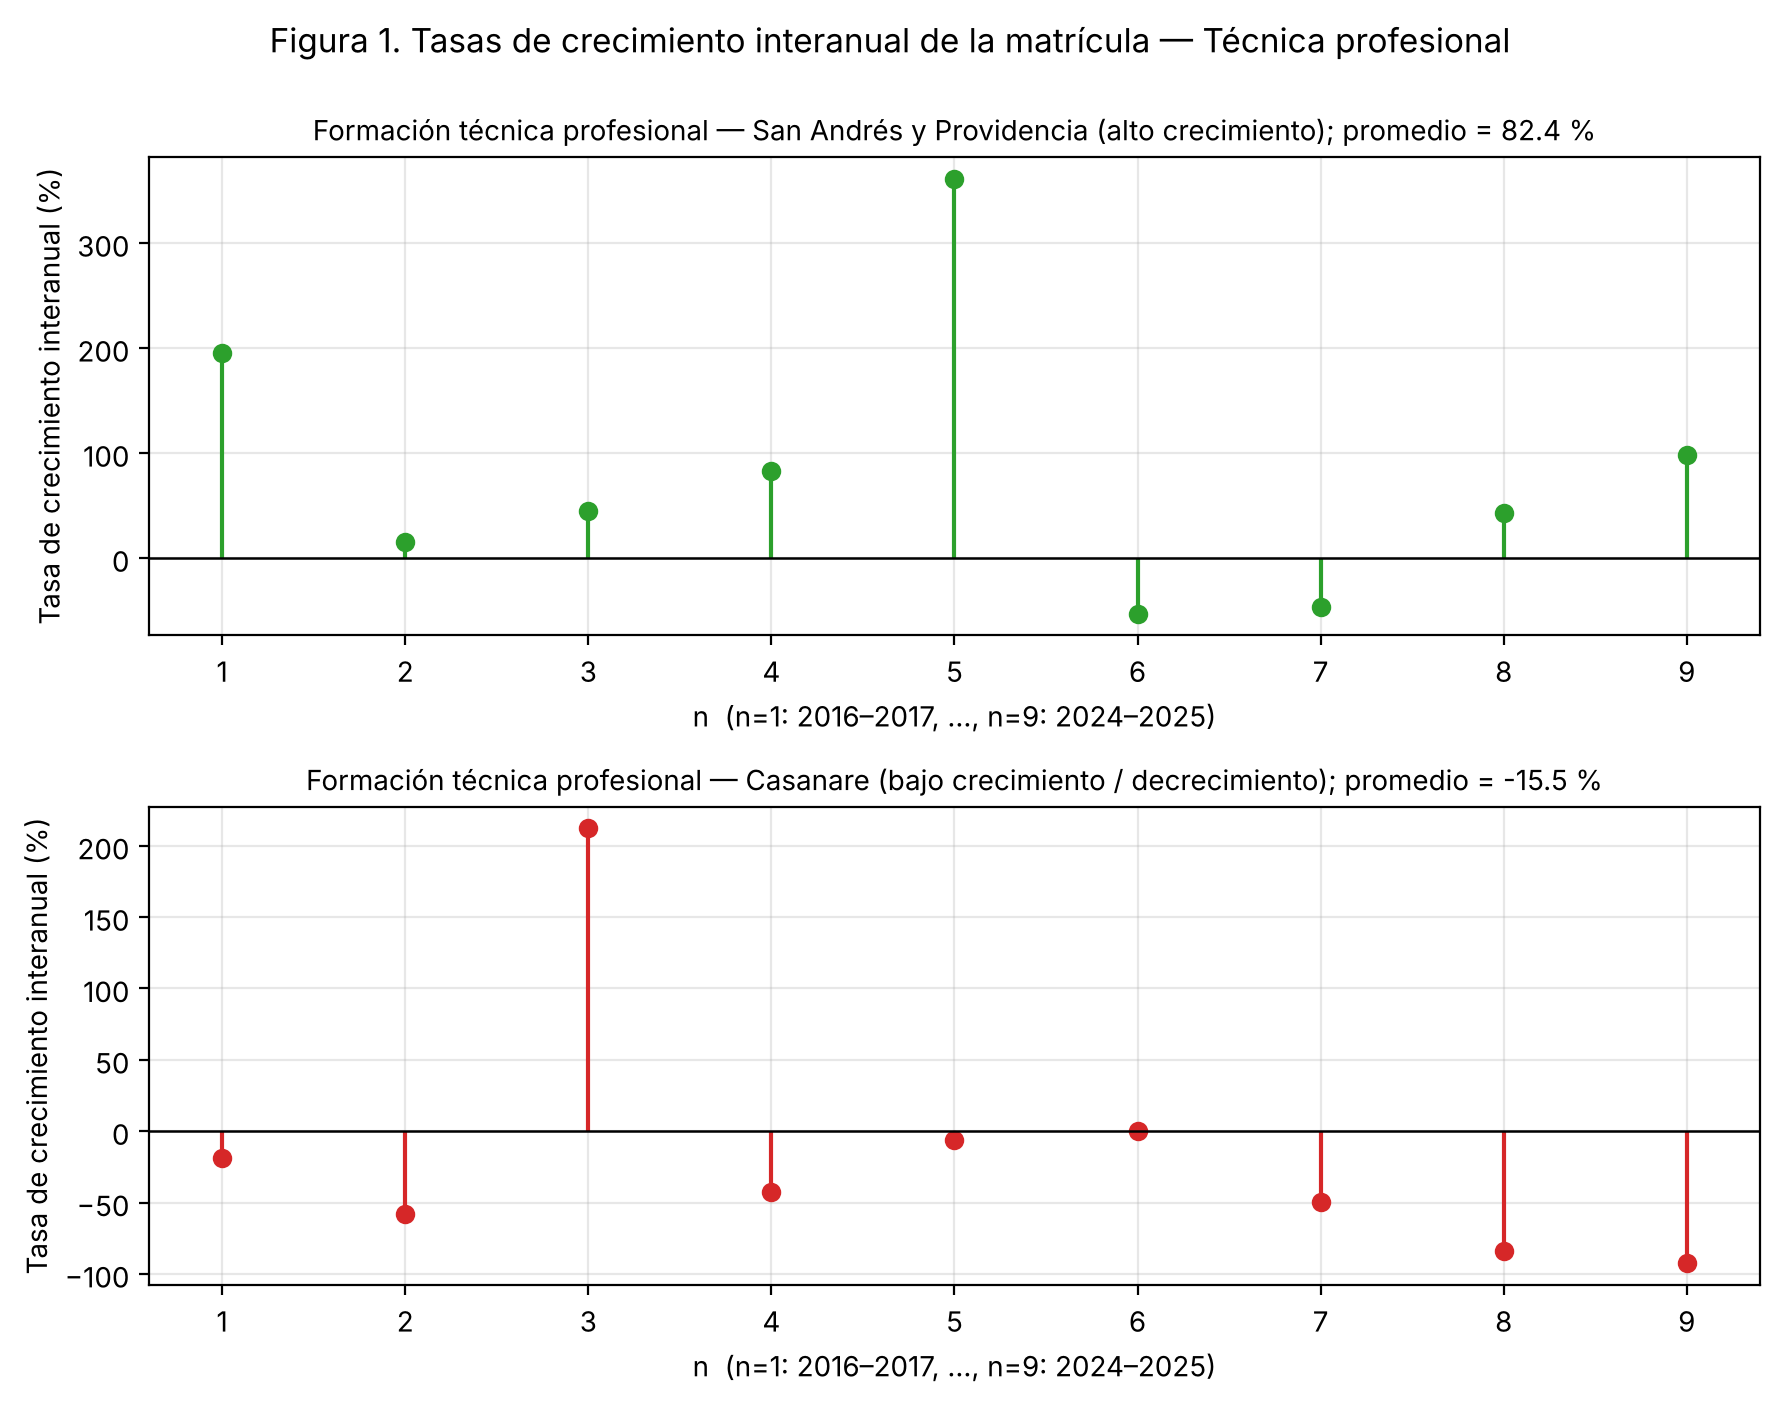

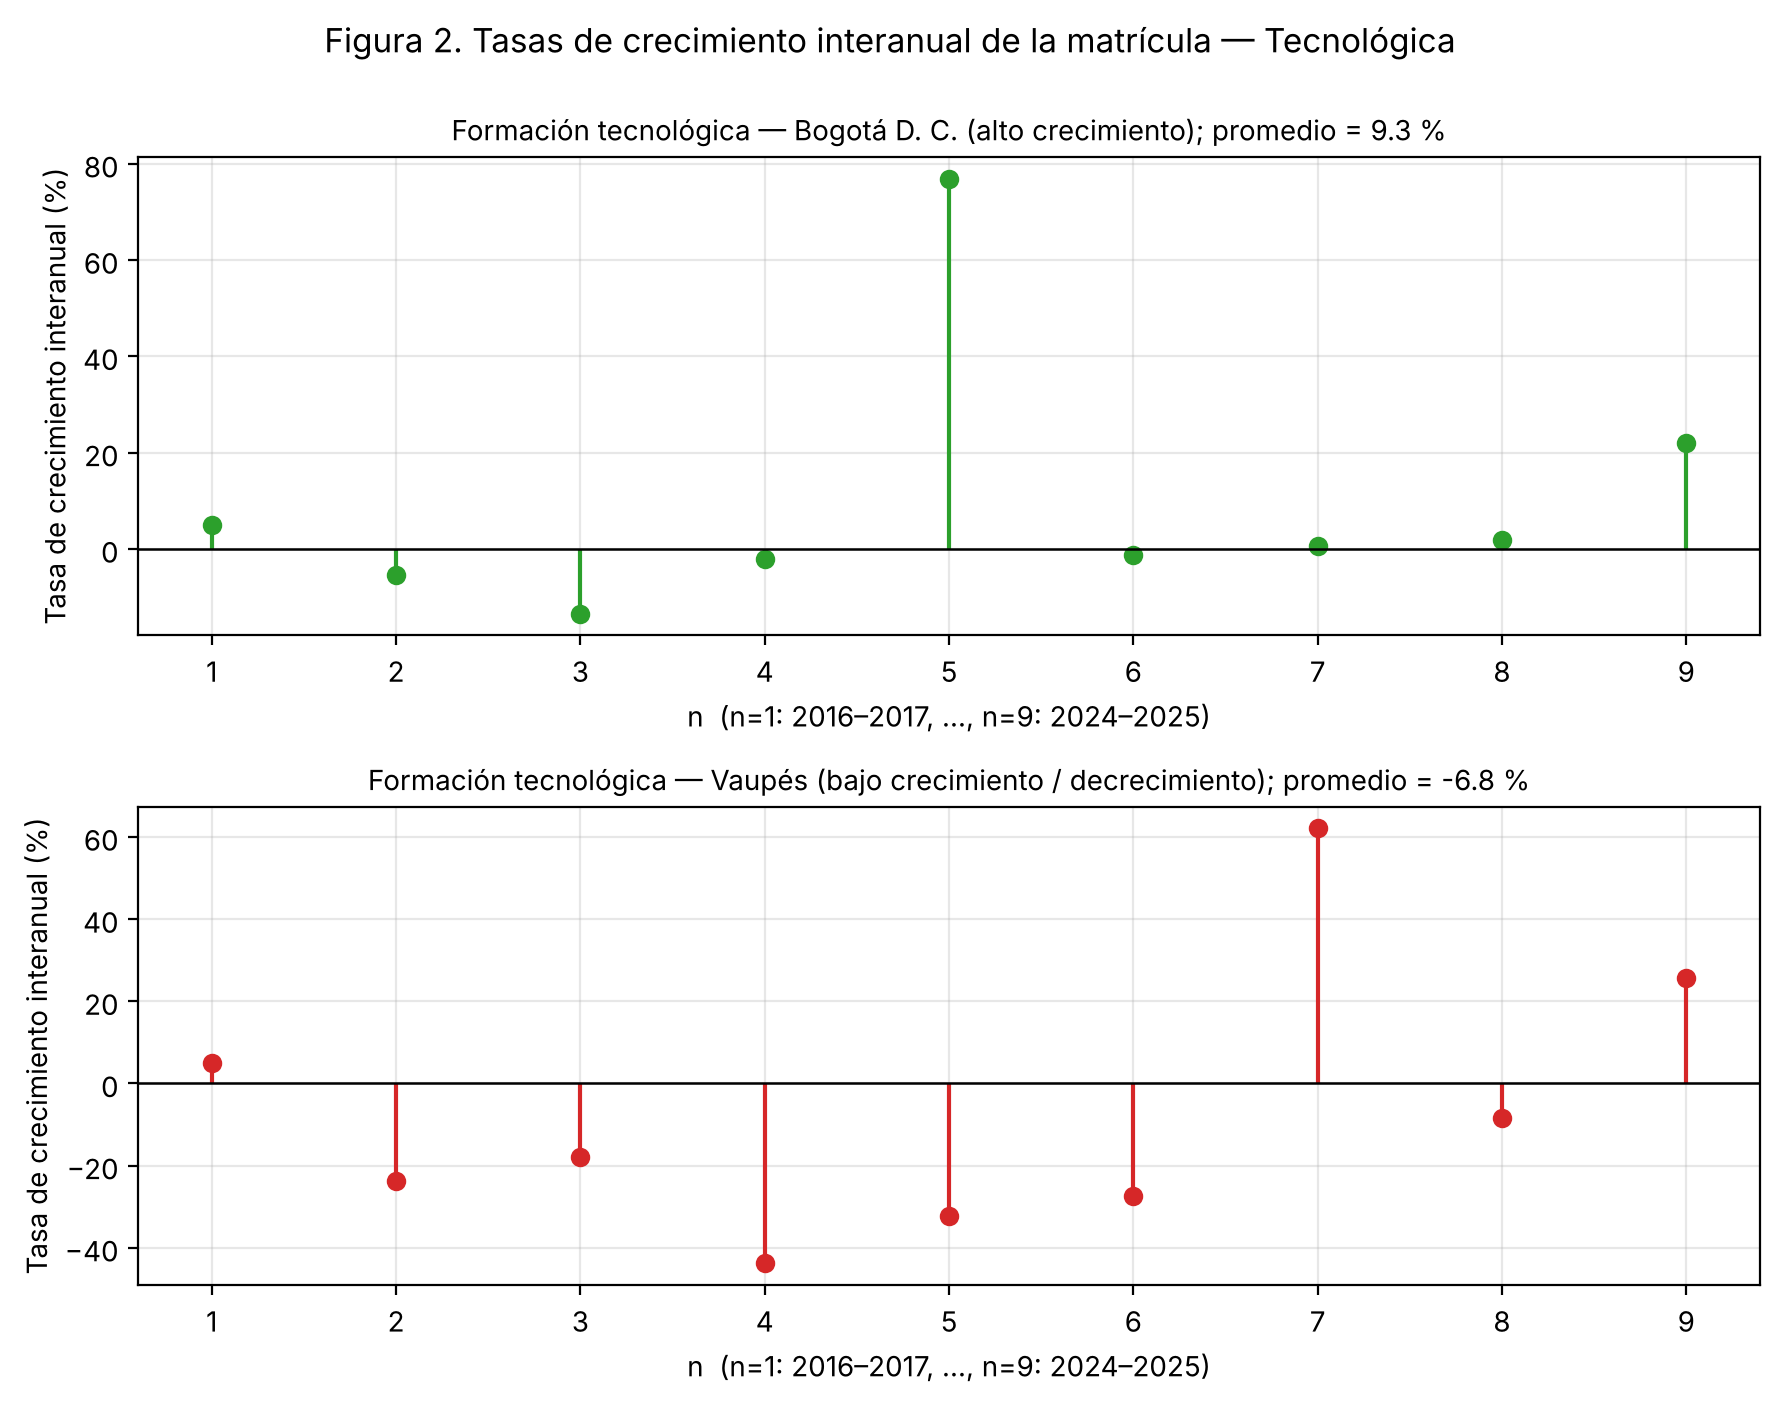

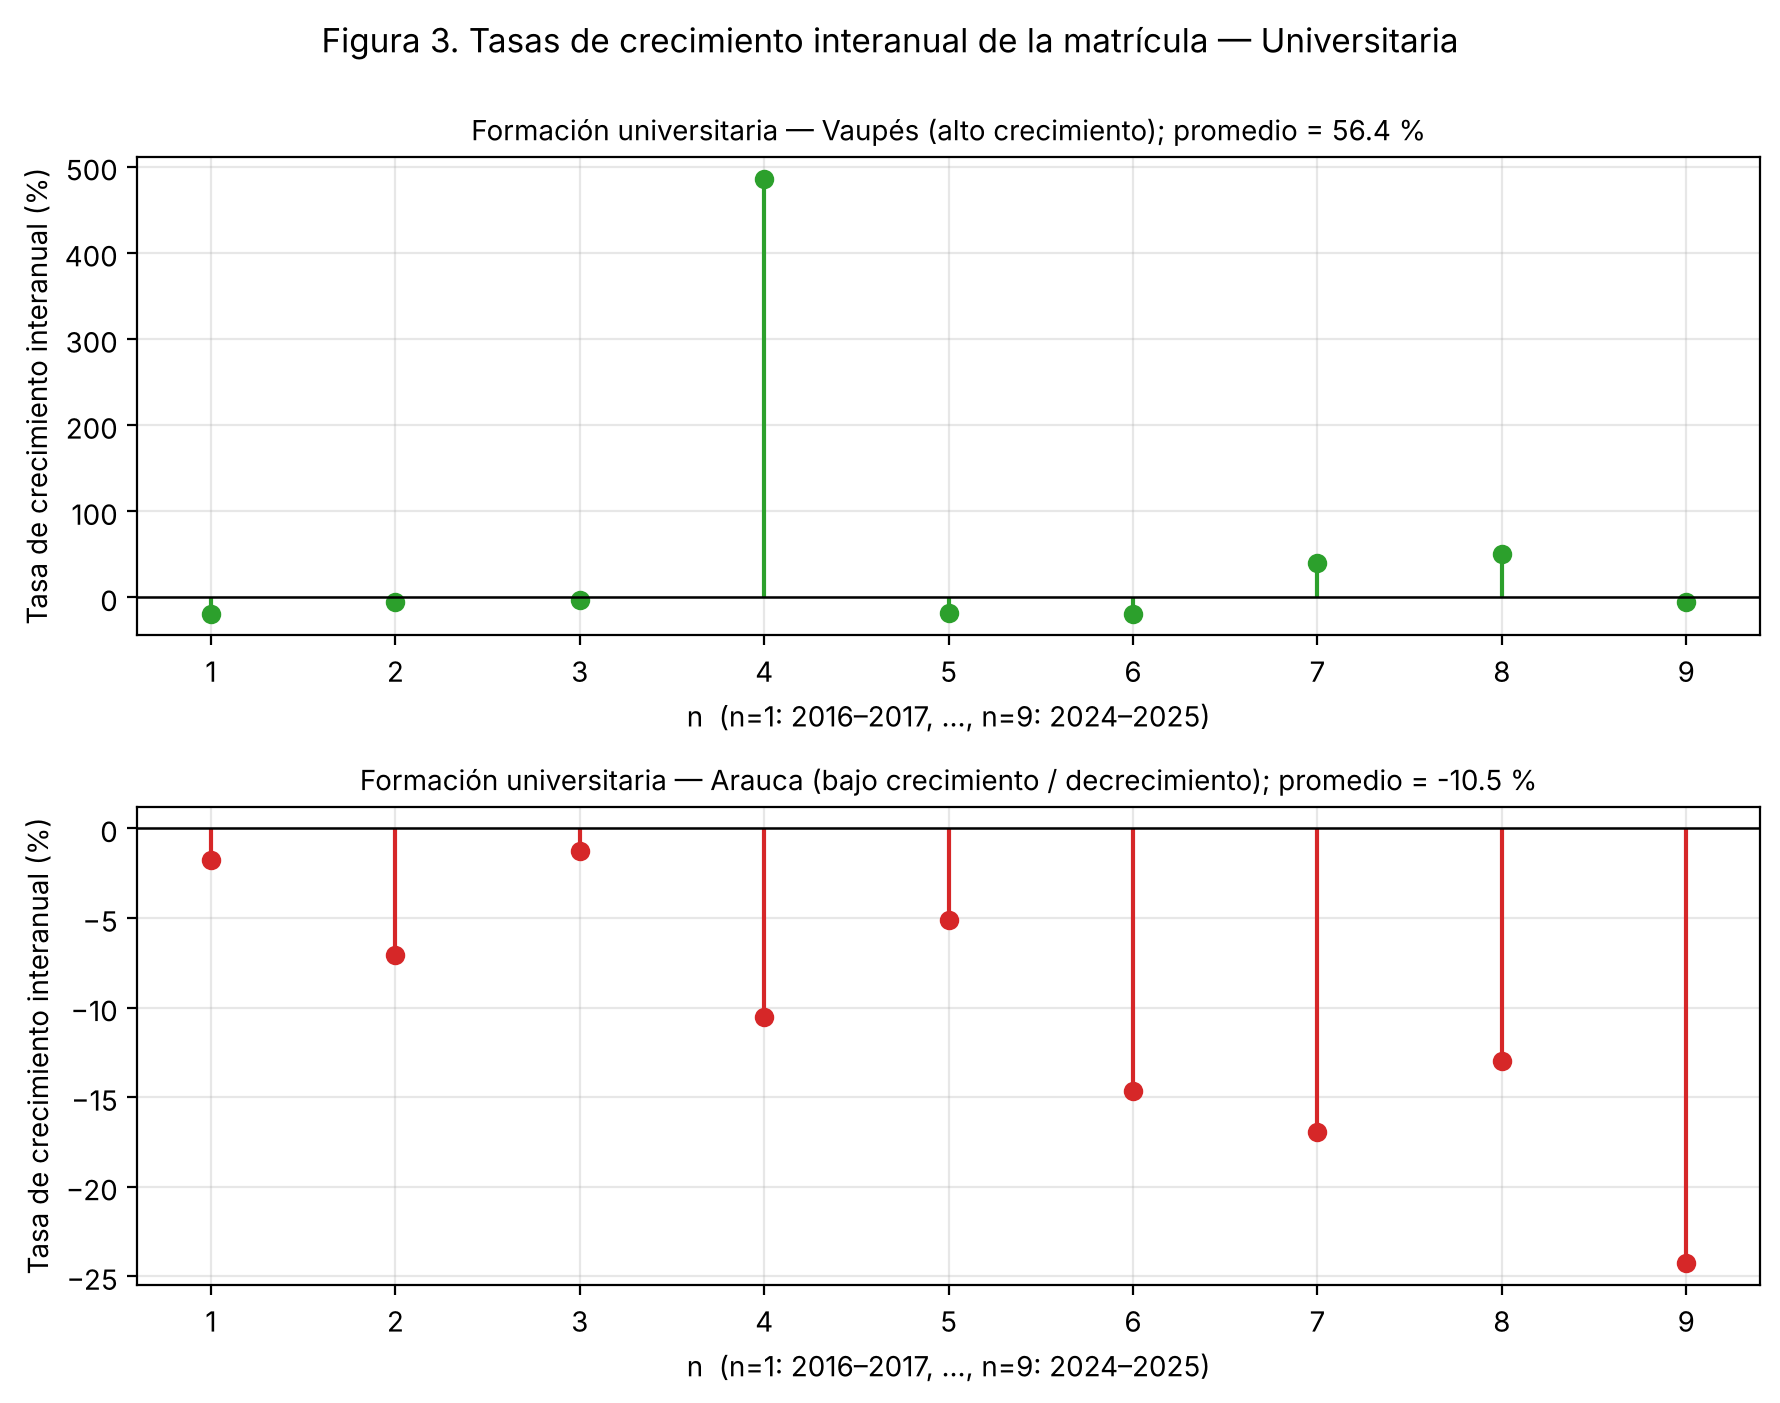

In [14]:
def describir(y, nombre=None):
    """Resumen de una señal de 9 muestras: máximo, mínimo, cambios de signo y valores atípicos (regla de Tukey)."""
    y = np.asarray(y, float)
    q1, q3 = np.percentile(y, [25, 75]); iqr = q3 - q1
    atip = np.where((y < q1 - 1.5 * iqr) | (y > q3 + 1.5 * iqr))[0] + 1
    signo = np.sign(y[y != 0])
    return dict(señal=nombre, promedio=y.mean(), mediana=np.median(y),
                maximo=y.max(), n_max=int(y.argmax()) + 1, minimo=y.min(), n_min=int(y.argmin()) + 1,
                cambios_de_signo=int((signo[1:] != signo[:-1]).sum()),
                atipicos_n=",".join(map(str, atip)) if len(atip) else "-")

def stem_senal(ax, y, titulo, ylabel, marcar=None, color="C0"):
    n = np.arange(1, 10)
    ml, sl, bl = ax.stem(n, y, basefmt=" ")
    plt.setp(ml, color=color); plt.setp(sl, color=color)
    ax.axhline(0, color="k", lw=0.9)
    if marcar is not None and np.any(marcar):
        idx = np.where(marcar)[0]
        ax.plot(n[idx], np.asarray(y)[idx], "o", mfc="none", mec="red", ms=13, mew=1.6, label="valor estimado")
        ax.legend(loc="best", fontsize=8)
    ax.set_xticks(n)
    ax.set_xlabel("n  (n=1: 2016–2017, …, n=9: 2024–2025)")
    ax.set_ylabel(ylabel); ax.set_title(titulo, fontsize=10); ax.grid(alpha=0.3)

def senal_d2(dep, nivel):
    fila = d2[(d2.departamento == dep) & (d2.nivel == nivel)].iloc[0]
    marcas = np.array([(dep, nivel, i) in est_set for i in INTERVALOS])
    return fila[INTERVALOS].values.astype(float), marcas

resumen = []
for k, (nivel, (alto, bajo)) in enumerate(seleccion.items(), start=1):
    fig, axs = plt.subplots(2, 1, figsize=(9, 7))
    for ax, dep, etiqueta, color in [(axs[0], alto, "alto crecimiento", "C2"), (axs[1], bajo, "bajo crecimiento / decrecimiento", "C3")]:
        y, marcas = senal_d2(dep, nivel)
        m = d2[(d2.departamento == dep) & (d2.nivel == nivel)].iloc[0]
        stem_senal(ax, y, f"Formación {nivel.lower()} — {dep} ({etiqueta}); promedio = {m.media:.1f} %", "Tasa de crecimiento interanual (%)", marcas, color)
        resumen.append(describir(y, f"{nivel} · {dep} ({etiqueta})"))
    fig.suptitle(f"Figura {k}. Tasas de crecimiento interanual de la matrícula — {nivel}", fontsize=12, y=0.995)
    fig.tight_layout(); fig.savefig(f"figuras/fig{k}_crecimiento_{list(NIVELES)[k-1]}.png", dpi=150); plt.show()

### Análisis de las Figuras 1 a 3 (tasas de crecimiento por nivel)

**Justificación de la selección.** Para cada nivel se tomó el mayor y el menor promedio de las nueve tasas entre las filas **sin valores estimados** (técnica: 20 candidatas; tecnológica y universitaria: 33). Los promedios y las medianas de los candidatos extremos están en las tablas de arriba. Las señales descriptivas (máximo, mínimo, cambios de signo, atípicos por la regla de Tukey) se resumen en la tabla de la subsección 3.2.

**Técnica profesional (Figura 1).**
- *San Andrés y Providencia (alto; promedio 82,4 %, mediana 45,3 %).* Máximo de **+361,3 % en n=5** (2020–2021: de 199 a 918 matriculados), el único atípico de la señal; mínimo de −52,8 % en n=6 y dos cambios de signo (n=6 y n=7 negativos). En los dos intervalos posteriores a 2023 crece +43,0 % y +98,5 % (230 → 329 → 653).
- *Casanare (bajo; promedio −15,5 %, mediana −42,6 %).* Un pico de **+212,1 % en n=3** (2018–2019: de 297 a 927) y, fuera de él, caídas casi continuas hasta **−83,8 % y −92,7 %** en los dos últimos intervalos (de 253 a 41 y a 3 matriculados). Su matrícula pasó de 869 en 2016 a 3 en 2025.
- **Interpretación.** En ambos casos el promedio y la mediana difieren mucho (82,4 vs 45,3 y −15,5 vs −42,6): los picos aislados distorsionan el promedio. Para Casanare el promedio *subestima* la caída típica. Las bases son de cientos de estudiantes, así que las tasas reflejan cambios de pocas decenas de personas.

**Tecnológica (Figura 2).**
- *Bogotá D. C. (alto; promedio 9,3 %, mediana 0,5 %).* En la mayoría de intervalos la matrícula casi no cambia (|g| < 14 %); el promedio lo definen dos episodios: **+76,9 % en n=5** (2020–2021: de 143 609 a 254 058) y +22,0 % en n=9. Mínimo de −13,4 % en n=3, cuatro cambios de signo y tres valores atípicos (n=3, 5 y 9).
- *Vaupés (bajo; promedio −6,8 %, mediana −18,0 %).* Caídas sostenidas entre n=2 y n=6 (−24 %, −18 %, −44 %, −32 %, −28 %), con mínimo de −43,8 % en n=4, seguidas de un rebote de **+62,1 % en n=7** (de 29 a 47), atípico. Su matrícula tecnológica pasó de 160 (2016) a 54 (2025).
- **Hecho observado.** En Bogotá, el salto de 2020–2021 coincide con un aumento de la participación oficial de 30,7 % a 40,7 % (Dataset 1). **Hipótesis por verificar:** que corresponda a un cambio en el reporte o la oferta del sector oficial; no se puede afirmar con estos datos.

**Universitaria (Figura 3).**
- *Vaupés (alto; promedio 56,4 %, mediana −5,1 %).* El promedio se debe casi por completo a **+486,1 % en n=4** (2019–2020: de 36 a 211 matriculados), atípico. Sin ese intervalo la señal es mayormente negativa o cercana a cero (mediana −5,1 %), con 40 % y 51 % en n=7 y n=8 (140 → 196 → 296). **Es un salto estructural y no un crecimiento sostenido**; se mantiene en la figura porque el criterio de la guía es el promedio, pero **Vichada (promedio 21,6 %, mediana 17,6 %) o Putumayo (17,4 % y 18,1 %)** ilustrarían mejor un crecimiento sostenido, y el equipo puede preferirlos.
- *Arauca (bajo; promedio y mediana −10,5 %).* **Las nueve tasas son negativas** (de −1,2 % en n=3 a −24,3 % en n=9), sin cambios de signo y sin atípicos: es la única señal de las ocho con descenso continuo. La matrícula universitaria bajó de 1 847 (2016) a 661 (2025), −64 %. **Hecho observado:** en el mismo periodo la participación oficial de Arauca subió de 39,3 % a 96,9 %. **Hipótesis por verificar:** reducción u cierre de oferta privada.

**Patrones generales.** (i) Las señales de las bases pequeñas son impulsivas: uno o dos intervalos concentran el valor extremo. (ii) Hay cambios de signo frecuentes (hasta cuatro) en tecnológica y universitaria de los departamentos pequeños, y ninguno en el descenso sostenido de Arauca. (iii) El promedio es sensible a los atípicos, por eso se reporta también la mediana.

### 3.2 Variación de la participación del sector oficial
Se selecciona el departamento con el **mayor aumento acumulado** y el de la **mayor disminución acumulada** (suma de las nueve variaciones en pp, equivalente a $O_{2025}-O_{2016}$).

Mayor aumento acumulado:


,departamento,acumulado_pp
2,Arauca,57.6
9,Casanare,46.2
0,Amazonas,40.7


Mayor disminución acumulada:


,departamento,acumulado_pp
31,Vaupés,-71.3
15,Guainía,-9.9
13,Cundinamarca,-1.4


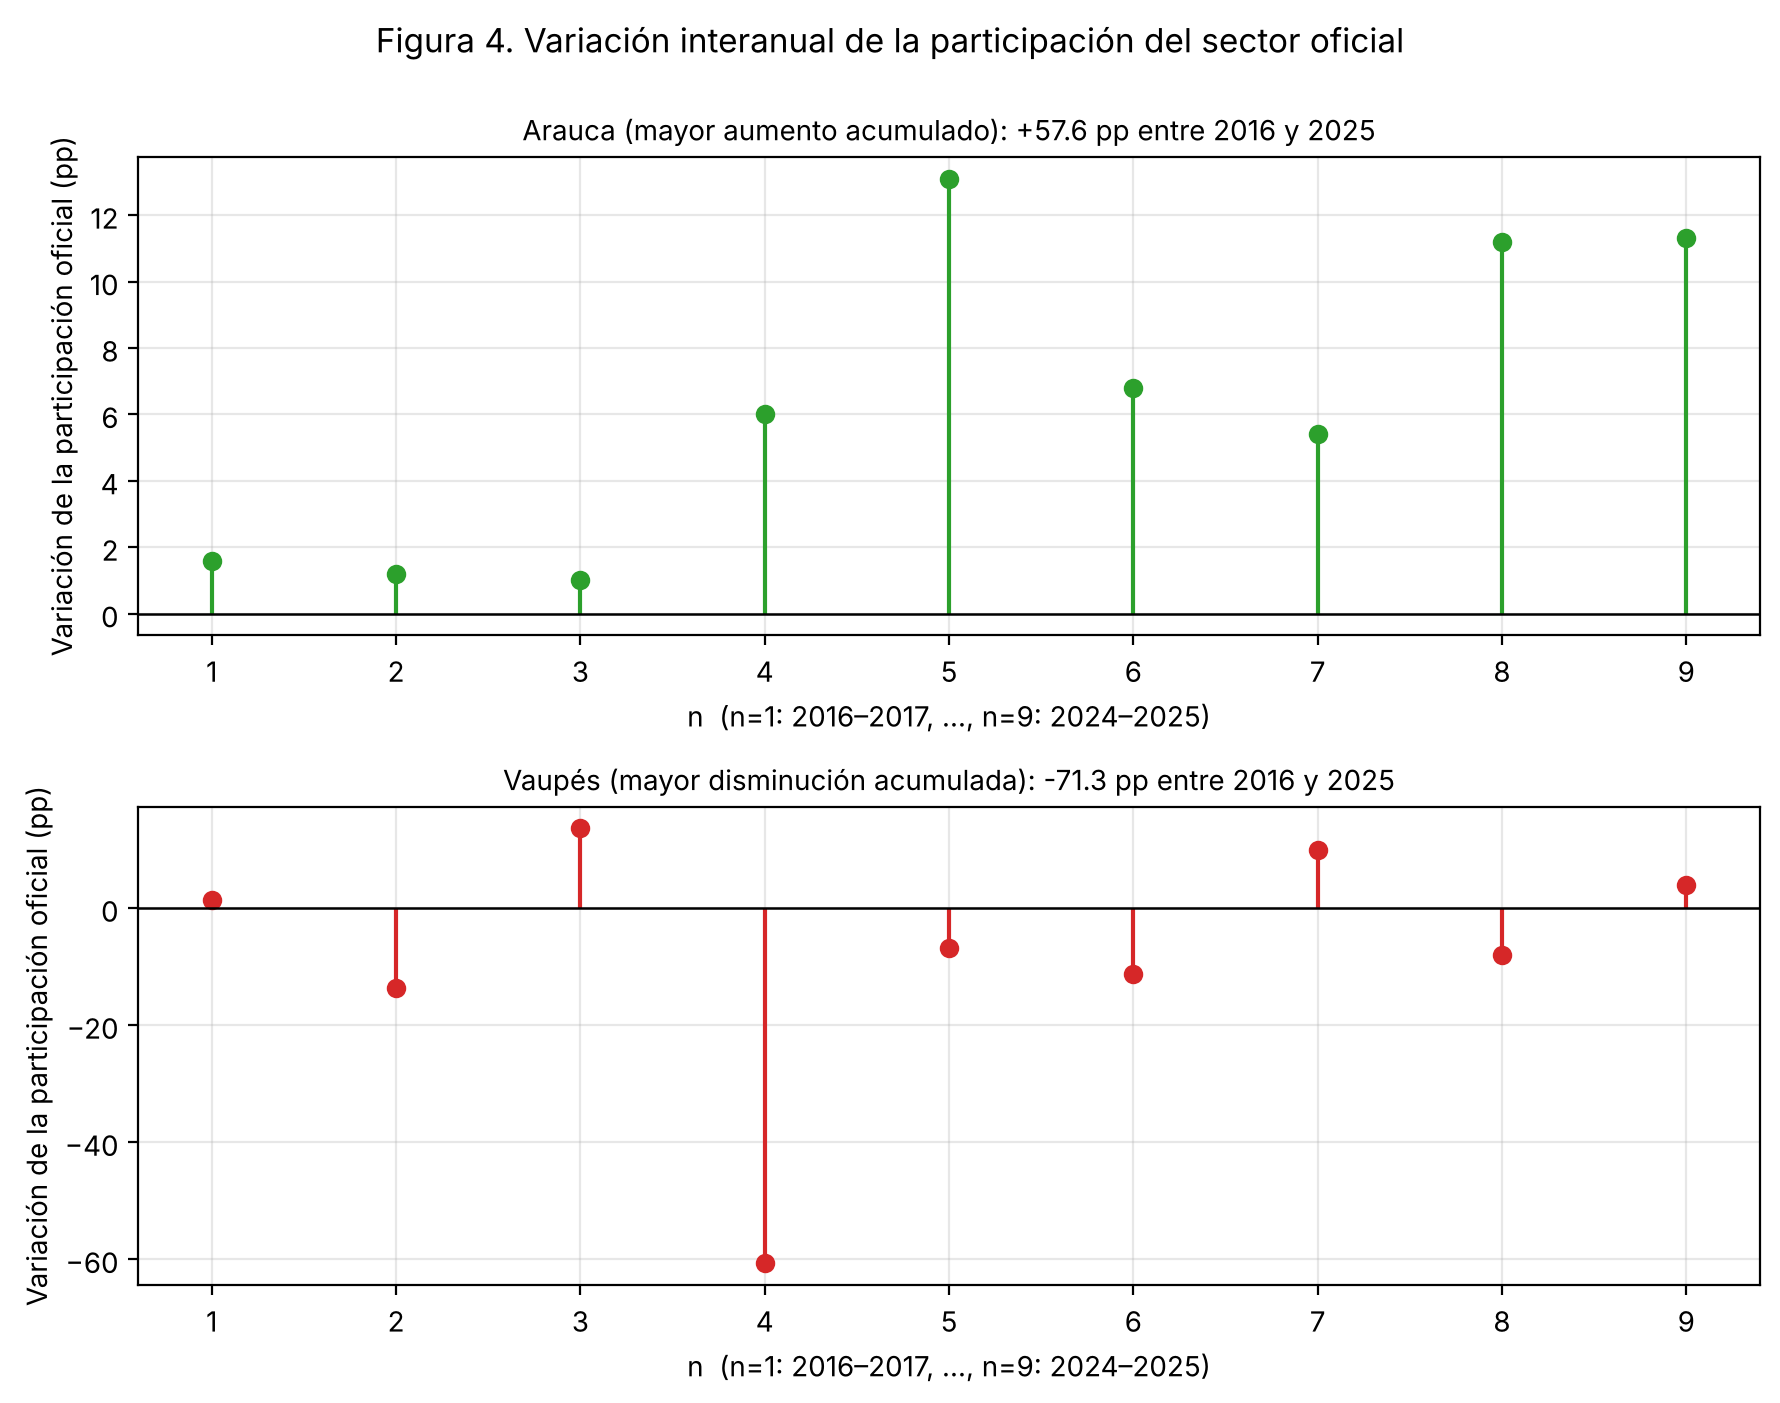


Oficial 2016 → 2025 (%):


departamento,Arauca,Vaupés
año,,
2016,39.3,98.6
2019,43.1,100.0
2020,49.1,39.3
2022,69.0,21.3
2023,74.4,31.3
2024,85.6,23.3
2025,96.9,27.3


In [15]:
d3["acumulado_pp"] = d3[INTERVALOS].sum(axis=1)
print("Mayor aumento acumulado:"); display(d3.sort_values("acumulado_pp", ascending=False).head(3)[["departamento", "acumulado_pp"]].round(1))
print("Mayor disminución acumulada:"); display(d3.sort_values("acumulado_pp").head(3)[["departamento", "acumulado_pp"]].round(1))
dep_up = d3.sort_values("acumulado_pp").iloc[-1].departamento
dep_down = d3.sort_values("acumulado_pp").iloc[0].departamento

fig, axs = plt.subplots(2, 1, figsize=(9, 7))
for ax, dep, etiqueta, color in [(axs[0], dep_up, "mayor aumento acumulado", "C2"), (axs[1], dep_down, "mayor disminución acumulada", "C3")]:
    y = d3[d3.departamento == dep][INTERVALOS].values[0]
    stem_senal(ax, y, f"{dep} ({etiqueta}): {y.sum():+.1f} pp entre 2016 y 2025", "Variación de la participación oficial (pp)", None, color)
    resumen.append(describir(y, f"Sector oficial · {dep} ({etiqueta})"))
fig.suptitle("Figura 4. Variación interanual de la participación del sector oficial", fontsize=12, y=0.995)
fig.tight_layout(); fig.savefig("figuras/fig4_variacion_sector_oficial.png", dpi=150); plt.show()

print("\nOficial 2016 → 2025 (%):")
display(d1[d1.departamento.isin([dep_up, dep_down]) & d1.año.isin([2016, 2019, 2020, 2022, 2023, 2024, 2025])]
        .pivot(index="año", columns="departamento", values="oficial"))

In [16]:
res = pd.DataFrame(resumen).set_index("señal")
res.round(1)

,promedio,mediana,maximo,n_max,minimo,n_min,cambios_de_signo,atipicos_n
señal,,,,,,,,
Técnica profesional · San Andrés y Providencia (alto crecimiento),82.4,45.3,361.3,5,-52.8,6,2,5
Técnica profesional · Casanare (bajo crecimiento / decrecimiento),-15.5,-42.6,212.1,3,-92.7,9,2,3
Tecnológica · Bogotá D. C. (alto crecimiento),9.3,0.5,76.9,5,-13.4,3,4,"3,5,9"
Tecnológica · Vaupés (bajo crecimiento / decrecimiento),-6.8,-18.0,62.1,7,-43.8,4,4,7
Universitaria · Vaupés (alto crecimiento),56.4,-5.1,486.1,4,-18.8,1,4,4
Universitaria · Arauca (bajo crecimiento / decrecimiento),-10.5,-10.5,-1.2,3,-24.3,9,0,-
Sector oficial · Arauca (mayor aumento acumulado),6.4,6.0,13.1,5,1.0,3,0,-
Sector oficial · Vaupés (mayor disminución acumulada),-7.9,-6.8,13.6,3,-60.7,4,6,4


### Análisis de la Figura 4 (participación del sector oficial)

- **Arauca (mayor aumento: +57,6 pp).** La participación oficial pasa de 39,3 % (2016) a 96,9 % (2025). **Las nueve variaciones son positivas** (mínimo +1,0 pp en n=3; máximo +13,1 pp en n=5, 2020–2021) y se aceleran al final: +11,2 pp y +11,3 pp en los dos últimos intervalos. Es una trayectoria monótona sin cambios de signo.
- **Vaupés (mayor disminución: −71,3 pp).** Pasa de 98,6 % a 27,3 %. La caída se concentra en un **cambio abrupto de −60,7 pp en n=4** (2019–2020: de 100,0 % a 39,3 %), atípico, precedido de una oscilación (−13,6 pp en n=2 y +13,6 pp en n=3). Después hay variaciones de −6,8, −11,2, +10,0, −8,0 y +4,0 pp; en total seis cambios de signo.
- **Comparación.** Ambos son territorios amazónicos u orinoquenses de matrícula pequeña, pero con trayectorias opuestas en forma y en sentido: Arauca es un desplazamiento gradual y continuo hacia el sector oficial; Vaupés es una ruptura única en 2020 y luego estabilidad con oscilaciones en un nivel bajo. **Hecho observado:** en Vaupés la matrícula universitaria pasa de 36 a 211 en el mismo intervalo en que la participación oficial cae. **Hipótesis por verificar:** entrada de matrícula en instituciones privadas, o de un nuevo oferente; con un total de pocas decenas de estudiantes, un solo programa mueve la participación decenas de puntos.

---
# Tarea 4. Agrupamiento de departamentos según sus patrones temporales

Cada departamento se representa con un vector de **9 características** (su señal). Se hacen cuatro agrupamientos independientes: técnica profesional, tecnológica y universitaria (Dataset 2) y variación del sector oficial (Dataset 3).

## Diseño metodológico

**Transformación.** Las tasas de crecimiento tienen colas muy pesadas (crecimientos de miles de % desde bases de pocas decenas de estudiantes), que dominarían cualquier distancia euclidiana. Se aplica $\operatorname{arcsinh}(x/s)$: es casi lineal para variaciones pequeñas (|x| ≲ s) y logarítmica para las extremas, conserva el signo y es continua en cero (el logaritmo simple no lo es). Escala $s=10\,\%$ para tasas de matrícula y $s=5$ pp para la variación del sector oficial. Las nueve características ya comparten unidades, por lo que no se estandariza por columna (hacerlo amplificaría intervalos poco informativos).

**Algoritmo y distancia.** **K-means** con **distancia euclidiana** sobre las señales transformadas: con n≈27–33 observaciones y d=9, es estable, interpretable (el centroide es una "señal tipo") y sus supuestos son razonables. No se usó DBSCAN (requiere elegir ε y densidad, poco fiable con tan pocos puntos en 9 dimensiones) ni mezclas gaussianas (demasiados parámetros de covarianza para n≈30).

**Atípicos.** Antes de agrupar se detectan departamentos aislados con la distancia al 3.er vecino más cercano y la regla de Tukey (Q3 + 1.5·IQR). Se reportan como **grupo aparte ("atípico")** y no participan del ajuste, para que un solo caso extremo no forme un grupo de un elemento ni distorsione los centroides.

**Número de grupos.** No hay k predeterminado: se evalúa k = 2…6 con el **coeficiente de silueta** y se exige un **tamaño mínimo de 3** departamentos por grupo (un grupo menor es un atípico, no un patrón). Se elige el k de mayor silueta bajo esa condición.

**Validación.** (i) Se compara con **agrupamiento jerárquico de Ward** mediante el índice de Rand ajustado (ARI); (ii) se visualiza en el plano de las dos primeras componentes principales (PCA) y con la señal mediana de cada grupo.

In [17]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

def detectar_atipicos(X, k_vecino=3):
    dist, _ = NearestNeighbors(n_neighbors=k_vecino + 1).fit(X).kneighbors(X)
    r = dist[:, -1]
    q1, q3 = np.percentile(r, [25, 75])
    return r > q3 + 1.5 * (q3 - q1)

def agrupar(X_original, nombres, escala, kmax=6, tam_min=3, semilla=0):
    X = np.arcsinh(np.asarray(X_original, float) / escala)
    atip = detectar_atipicos(X)
    Xi = X[~atip]
    filas = []
    for k in range(2, kmax + 1):
        km = KMeans(k, n_init=30, random_state=semilla).fit(Xi)
        wd = AgglomerativeClustering(k, linkage="ward").fit(Xi)
        tam = np.bincount(km.labels_)
        filas.append(dict(k=k, silueta_kmeans=silhouette_score(Xi, km.labels_), tam_min=int(tam.min()),
                          tamaños=sorted(tam.tolist(), reverse=True), silueta_ward=silhouette_score(Xi, wd.labels_),
                          ARI_kmeans_vs_ward=adjusted_rand_score(km.labels_, wd.labels_)))
    tabla = pd.DataFrame(filas)
    ok = tabla[tabla.tam_min >= tam_min]
    k_el = int(ok.loc[ok.silueta_kmeans.idxmax(), "k"])
    km = KMeans(k_el, n_init=30, random_state=semilla).fit(Xi)
    # Reetiquetar grupos 1..k por tamaño decreciente
    orden = np.argsort(-np.bincount(km.labels_)); remap = {int(o): i + 1 for i, o in enumerate(orden)}
    etiquetas = np.full(len(X), 0); etiquetas[~atip] = [remap[int(l)] for l in km.labels_]     # 0 = atípico
    pca = PCA(2).fit(Xi); coords = pca.transform(X)
    return dict(tabla=tabla, k=k_el, etiquetas=etiquetas, atipicos=list(np.array(nombres)[atip]),
                pca=coords, var_exp=pca.explained_variance_ratio_, X_original=np.asarray(X_original, float),
                nombres=np.array(nombres), silueta=float(ok.loc[ok.k == k_el, "silueta_kmeans"].iloc[0]),
                ari=float(ok.loc[ok.k == k_el, "ARI_kmeans_vs_ward"].iloc[0]))

PROBLEMAS = {}
for nivel in NIVELES.values():
    s = d2[d2.nivel == nivel]
    PROBLEMAS[nivel] = agrupar(s[INTERVALOS].values, s.departamento.values, escala=10)
PROBLEMAS["Sector oficial (pp)"] = agrupar(d3[INTERVALOS].values, d3.departamento.values, escala=5)

for nombre, r in PROBLEMAS.items():
    print(f"\n=== {nombre} (n={len(r['nombres'])}) ===")
    print(f"Atípicos detectados: {r['atipicos'] or 'ninguno'} | k elegido = {r['k']} | silueta = {r['silueta']:.3f} | ARI vs Ward = {r['ari']:.2f}")
    display(r["tabla"].round(3))


=== Técnica profesional (n=27) ===
Atípicos detectados: ['Cauca'] | k elegido = 2 | silueta = 0.262 | ARI vs Ward = 0.79


,k,silueta_kmeans,tam_min,tamaños,silueta_ward,ARI_kmeans_vs_ward
0,2,0.262,4,"[22, 4]",0.261,0.791
1,3,0.144,4,"[12, 10, 4]",0.188,0.191
2,4,0.149,4,"[8, 8, 6, 4]",0.203,0.224
3,5,0.132,2,"[10, 5, 5, 4, 2]",0.133,0.502
4,6,0.151,1,"[10, 4, 4, 4, 3, 1]",0.155,0.315



=== Tecnológica (n=33) ===
Atípicos detectados: ninguno | k elegido = 2 | silueta = 0.330 | ARI vs Ward = 0.70


,k,silueta_kmeans,tam_min,tamaños,silueta_ward,ARI_kmeans_vs_ward
0,2,0.330,6,"[27, 6]",0.343,0.700
1,3,0.148,4,"[15, 14, 4]",0.282,0.212
2,4,0.144,4,"[14, 10, 5, 4]",0.269,0.463
3,5,0.148,1,"[13, 12, 4, 3, 1]",0.146,0.754
4,6,0.161,1,"[13, 12, 3, 2, 2, 1]",0.158,0.750



=== Universitaria (n=33) ===
Atípicos detectados: ['Vaupés'] | k elegido = 2 | silueta = 0.485 | ARI vs Ward = 1.00


,k,silueta_kmeans,tam_min,tamaños,silueta_ward,ARI_kmeans_vs_ward
0,2,0.485,5,"[27, 5]",0.485,1.000
1,3,0.436,2,"[27, 3, 2]",0.436,1.000
2,4,0.386,1,"[25, 3, 3, 1]",0.426,0.882
3,5,0.296,1,"[22, 4, 3, 2, 1]",0.334,0.899
4,6,0.174,1,"[17, 9, 2, 2, 1, 1]",0.328,0.363



=== Sector oficial (pp) (n=33) ===
Atípicos detectados: ['Amazonas', 'Arauca', 'Casanare', 'Vaupés'] | k elegido = 3 | silueta = 0.157 | ARI vs Ward = 0.38


,k,silueta_kmeans,tam_min,tamaños,silueta_ward,ARI_kmeans_vs_ward
0,2,0.149,12,"[17, 12]",0.143,0.734
1,3,0.157,7,"[12, 10, 7]",0.145,0.384
2,4,0.125,1,"[11, 11, 6, 1]",0.125,0.475
3,5,0.132,1,"[9, 8, 6, 5, 1]",0.110,0.472
4,6,0.139,1,"[12, 5, 5, 4, 2, 1]",0.138,0.294


In [18]:
# Tabla de asignación de departamentos a grupos (los cuatro agrupamientos)
asig = []
for nombre, r in PROBLEMAS.items():
    for dep, g in zip(r["nombres"], r["etiquetas"]):
        asig.append(dict(agrupamiento=nombre, departamento=dep, grupo=("Atípico" if g == 0 else f"Grupo {g}")))
asig = pd.DataFrame(asig)
asig.to_csv("asignacion_grupos.csv", index=False, encoding="utf-8")

for nombre in PROBLEMAS:
    print(f"\n=== {nombre} ===")
    for g, sub in asig[asig.agrupamiento == nombre].groupby("grupo"):
        print(f"{g} ({len(sub)}): {', '.join(sub.departamento)}")


=== Técnica profesional ===
Atípico (1): Cauca
Grupo 1 (22): Amazonas, Antioquia, Atlántico, Bogotá D. C., Bolívar, Boyacá, Caldas, Chocó, Cundinamarca, Córdoba, Huila, La Guajira, Magdalena, Meta, Nariño, Norte de Santander, Risaralda, San Andrés y Providencia, Santander, Sucre, Tolima, Valle del Cauca
Grupo 2 (4): Caquetá, Casanare, Cesar, Quindío

=== Tecnológica ===
Grupo 1 (27): Amazonas, Antioquia, Atlántico, Bolívar, Boyacá, Caldas, Casanare, Cauca, Cesar, Cundinamarca, Córdoba, Guainía, Guaviare, Huila, La Guajira, Magdalena, Meta, Nariño, Norte de Santander, Quindío, Risaralda, San Andrés y Providencia, Santander, Sucre, Tolima, Valle del Cauca, Vichada
Grupo 2 (6): Arauca, Bogotá D. C., Caquetá, Chocó, Putumayo, Vaupés

=== Universitaria ===
Atípico (1): Vaupés
Grupo 1 (27): Amazonas, Antioquia, Arauca, Atlántico, Bogotá D. C., Bolívar, Boyacá, Caldas, Caquetá, Casanare, Cauca, Cesar, Chocó, Cundinamarca, Córdoba, Huila, La Guajira, Magdalena, Meta, Nariño, Norte de Santande

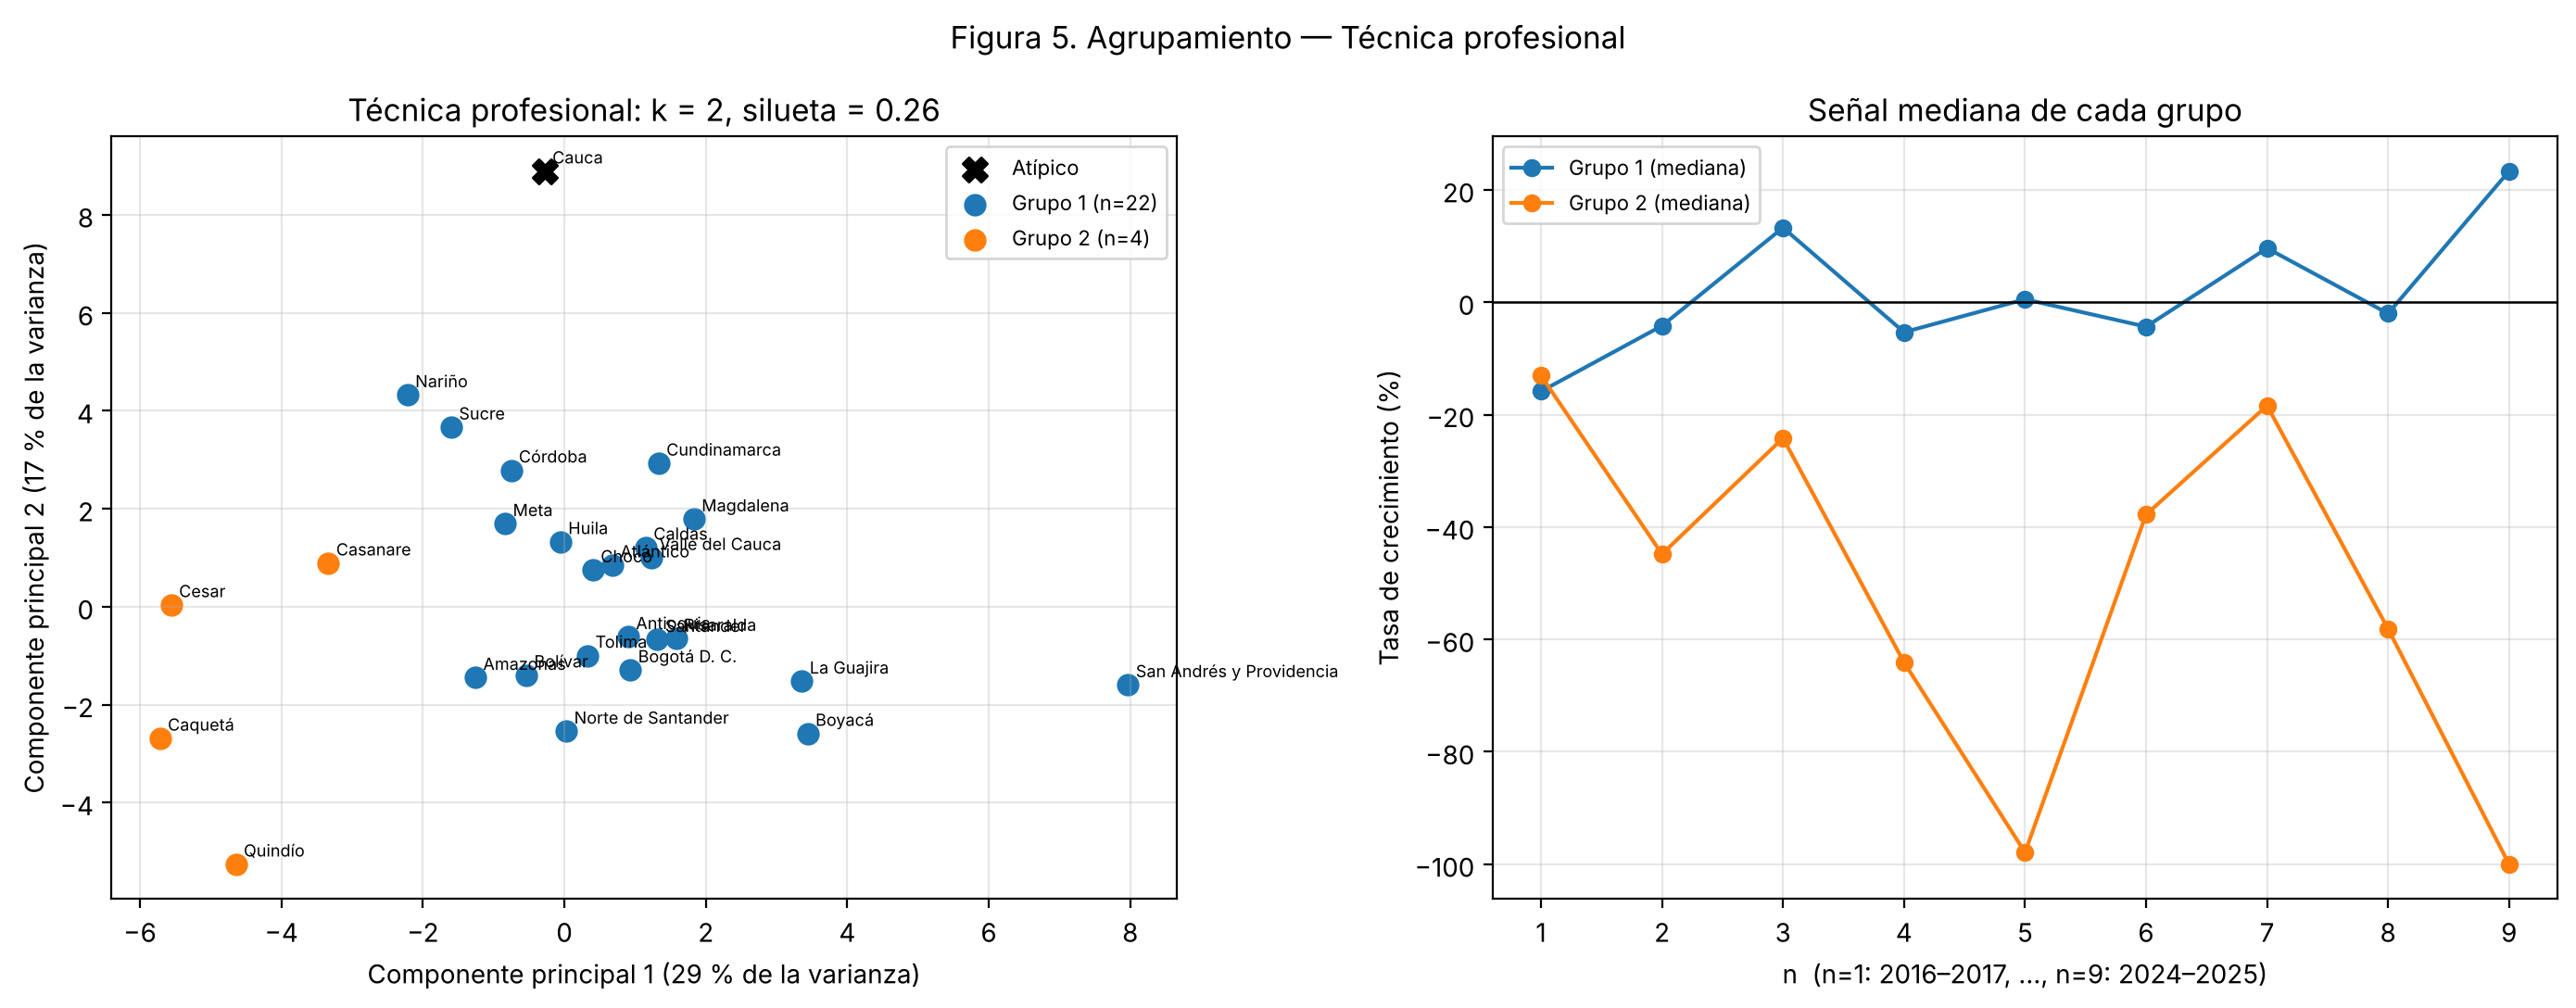

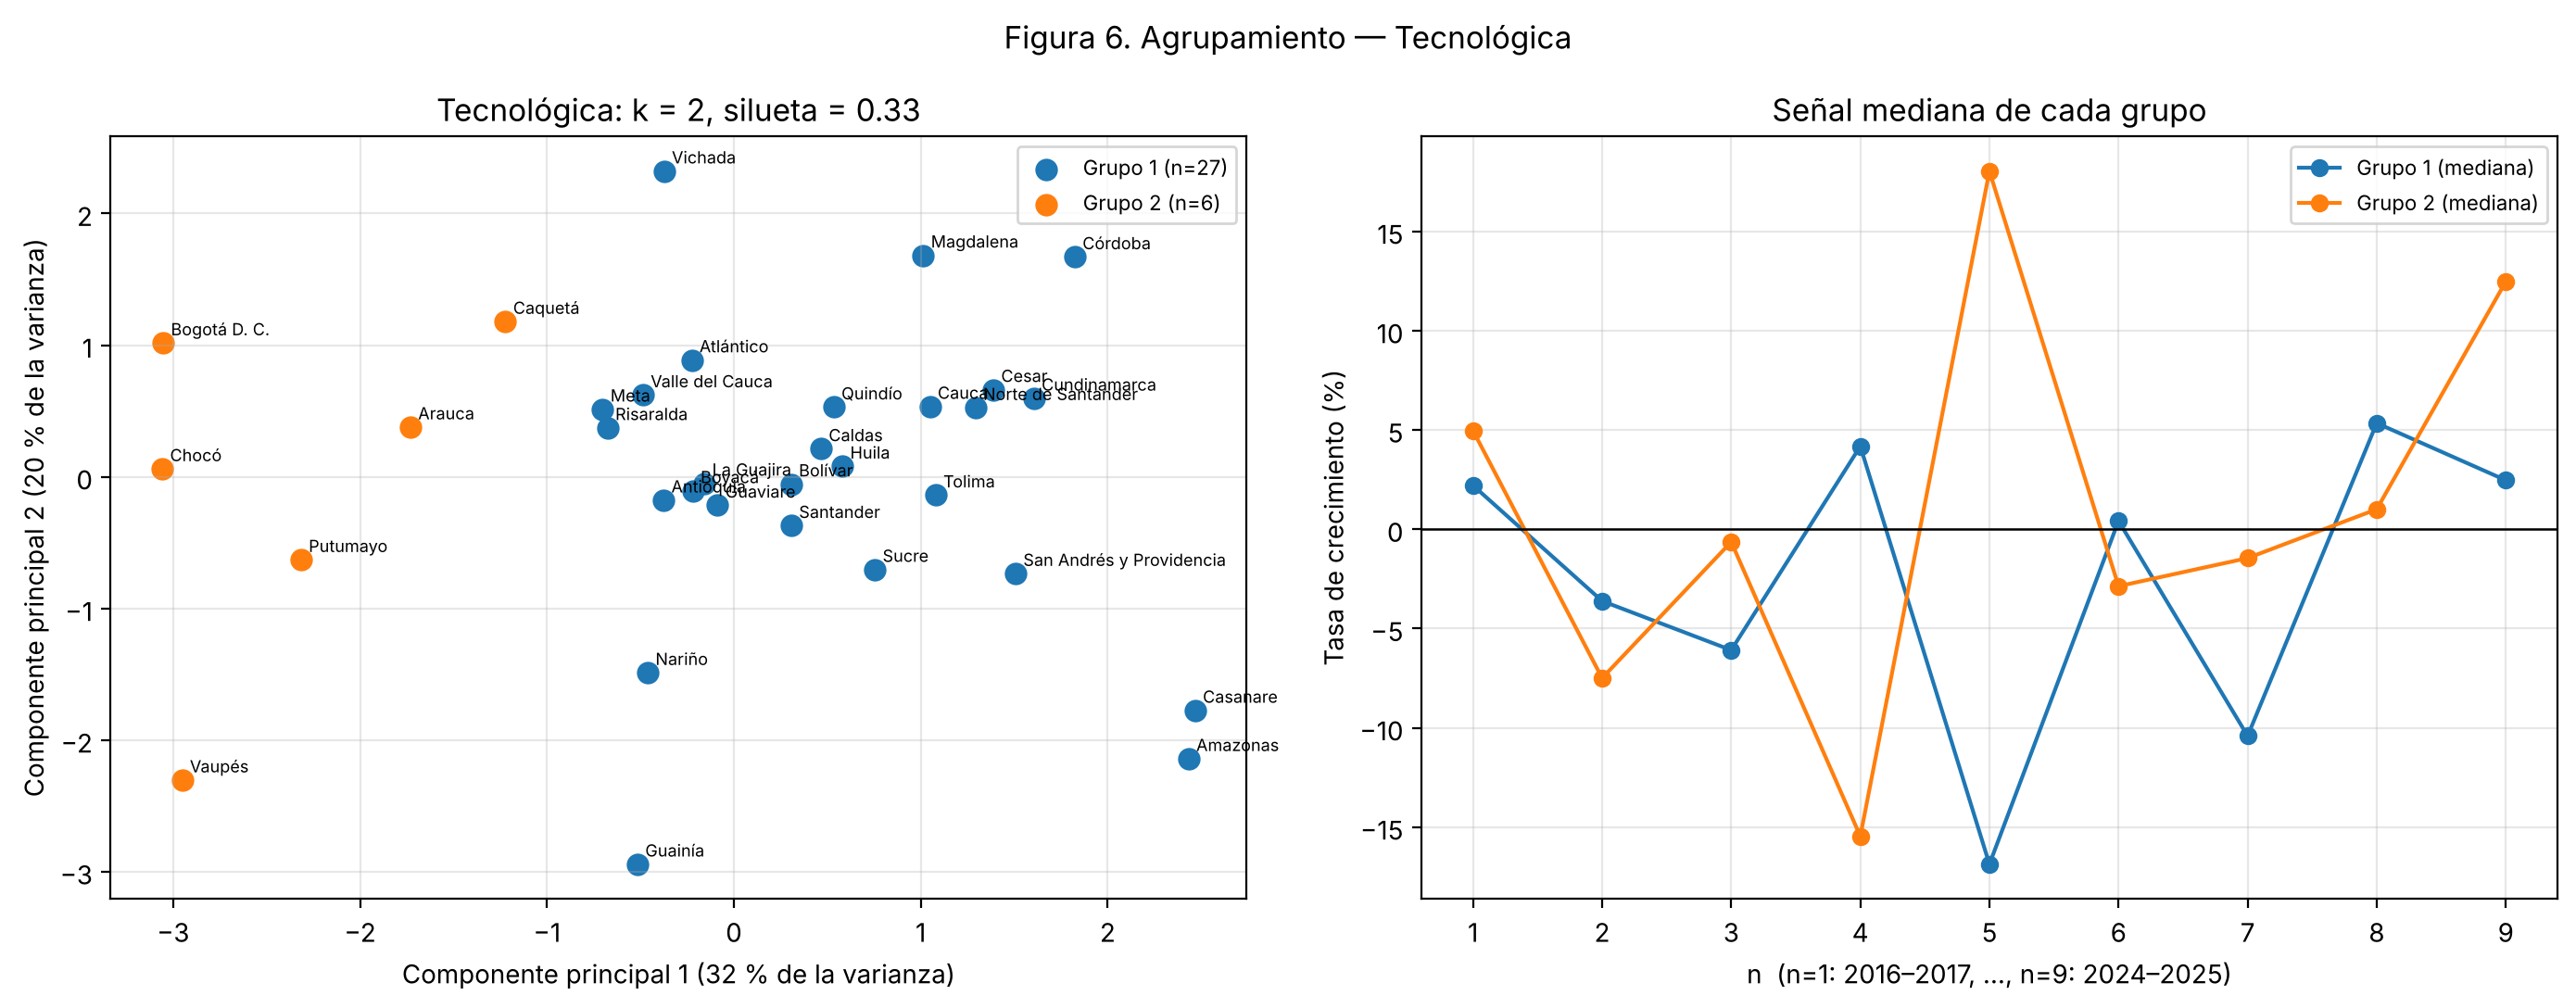

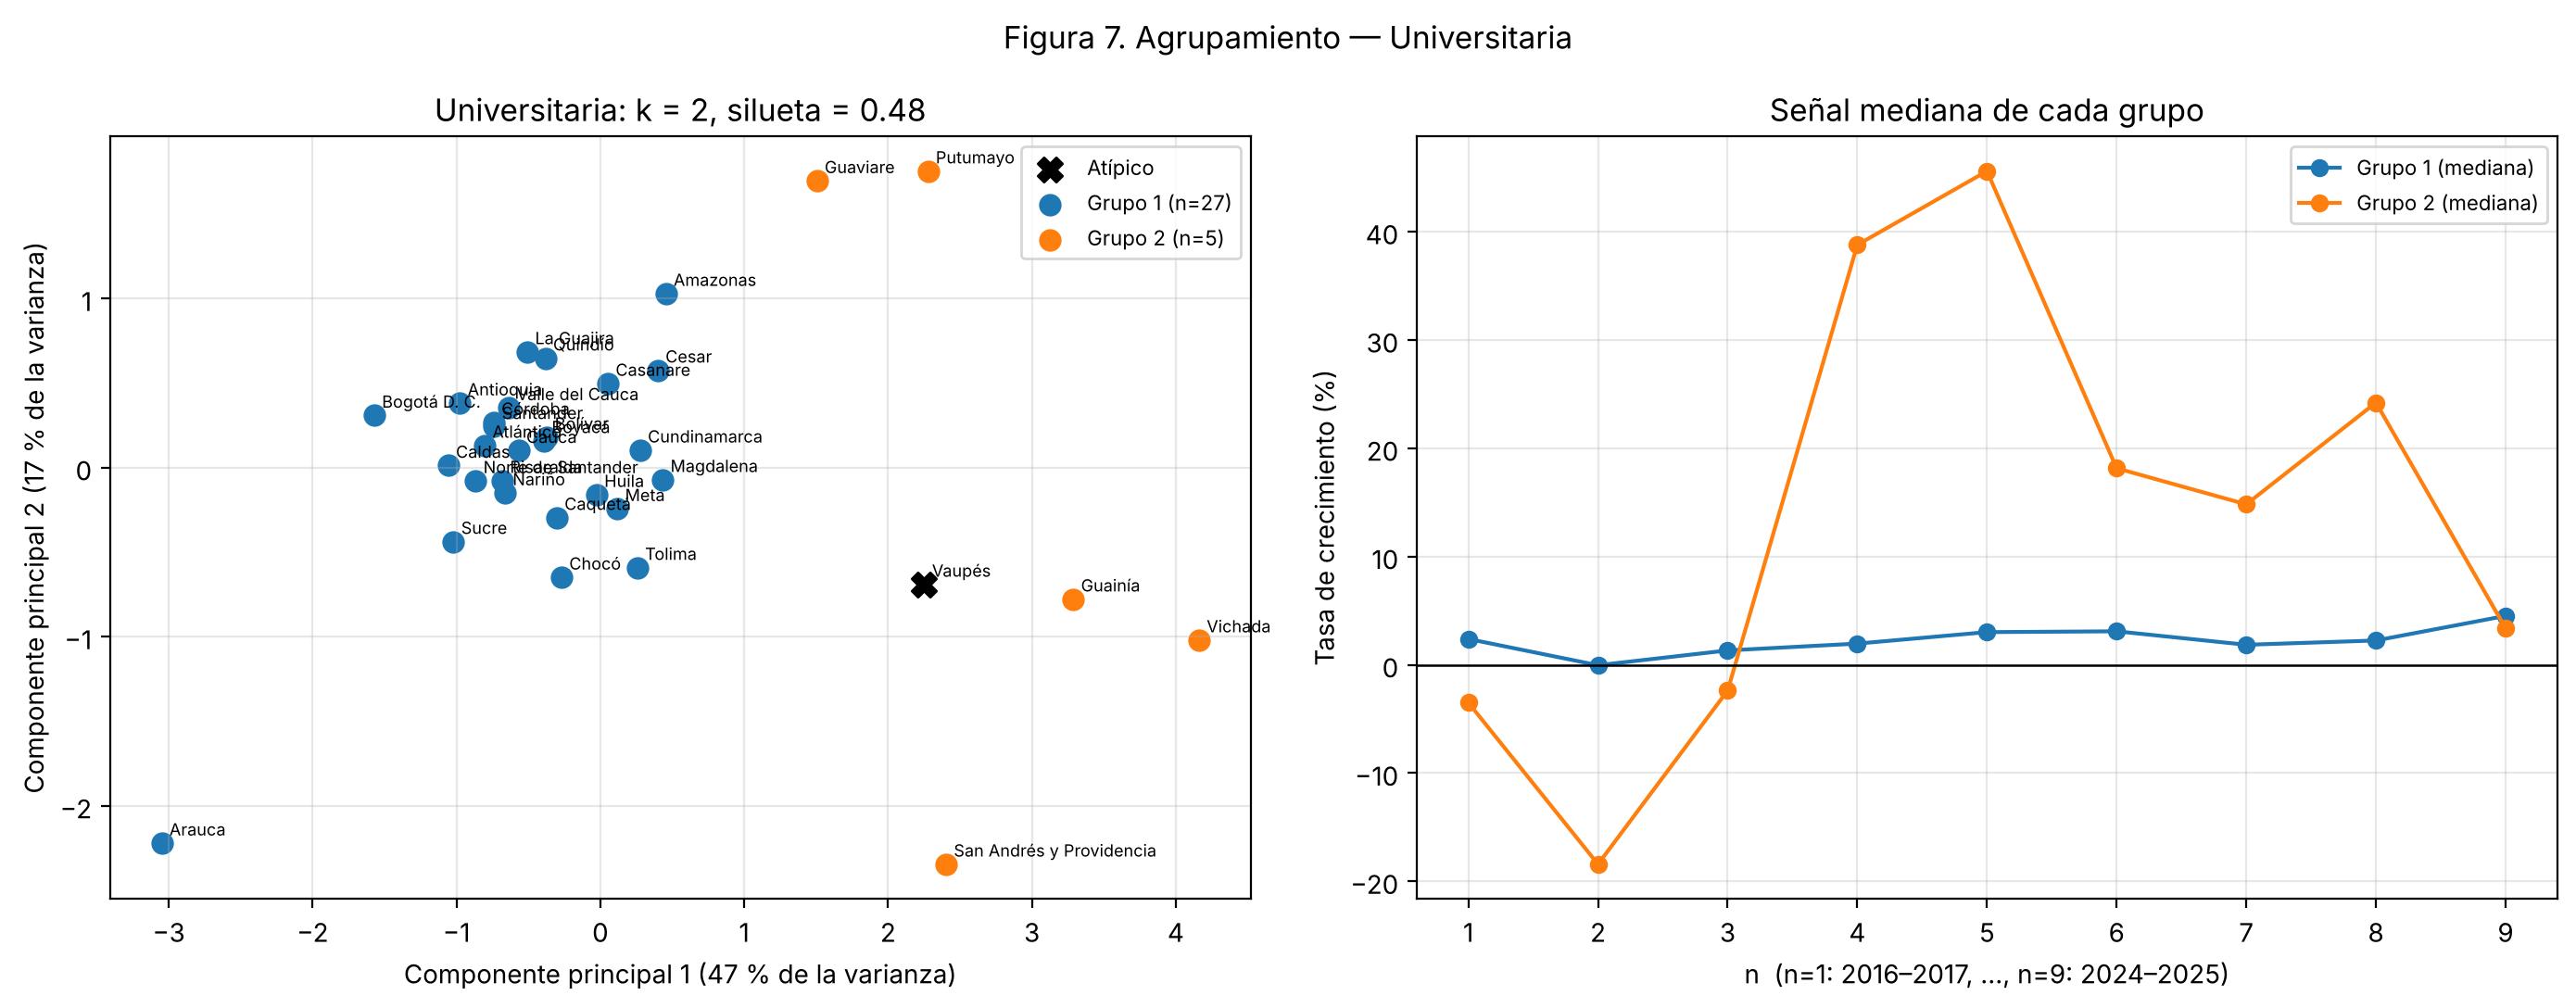

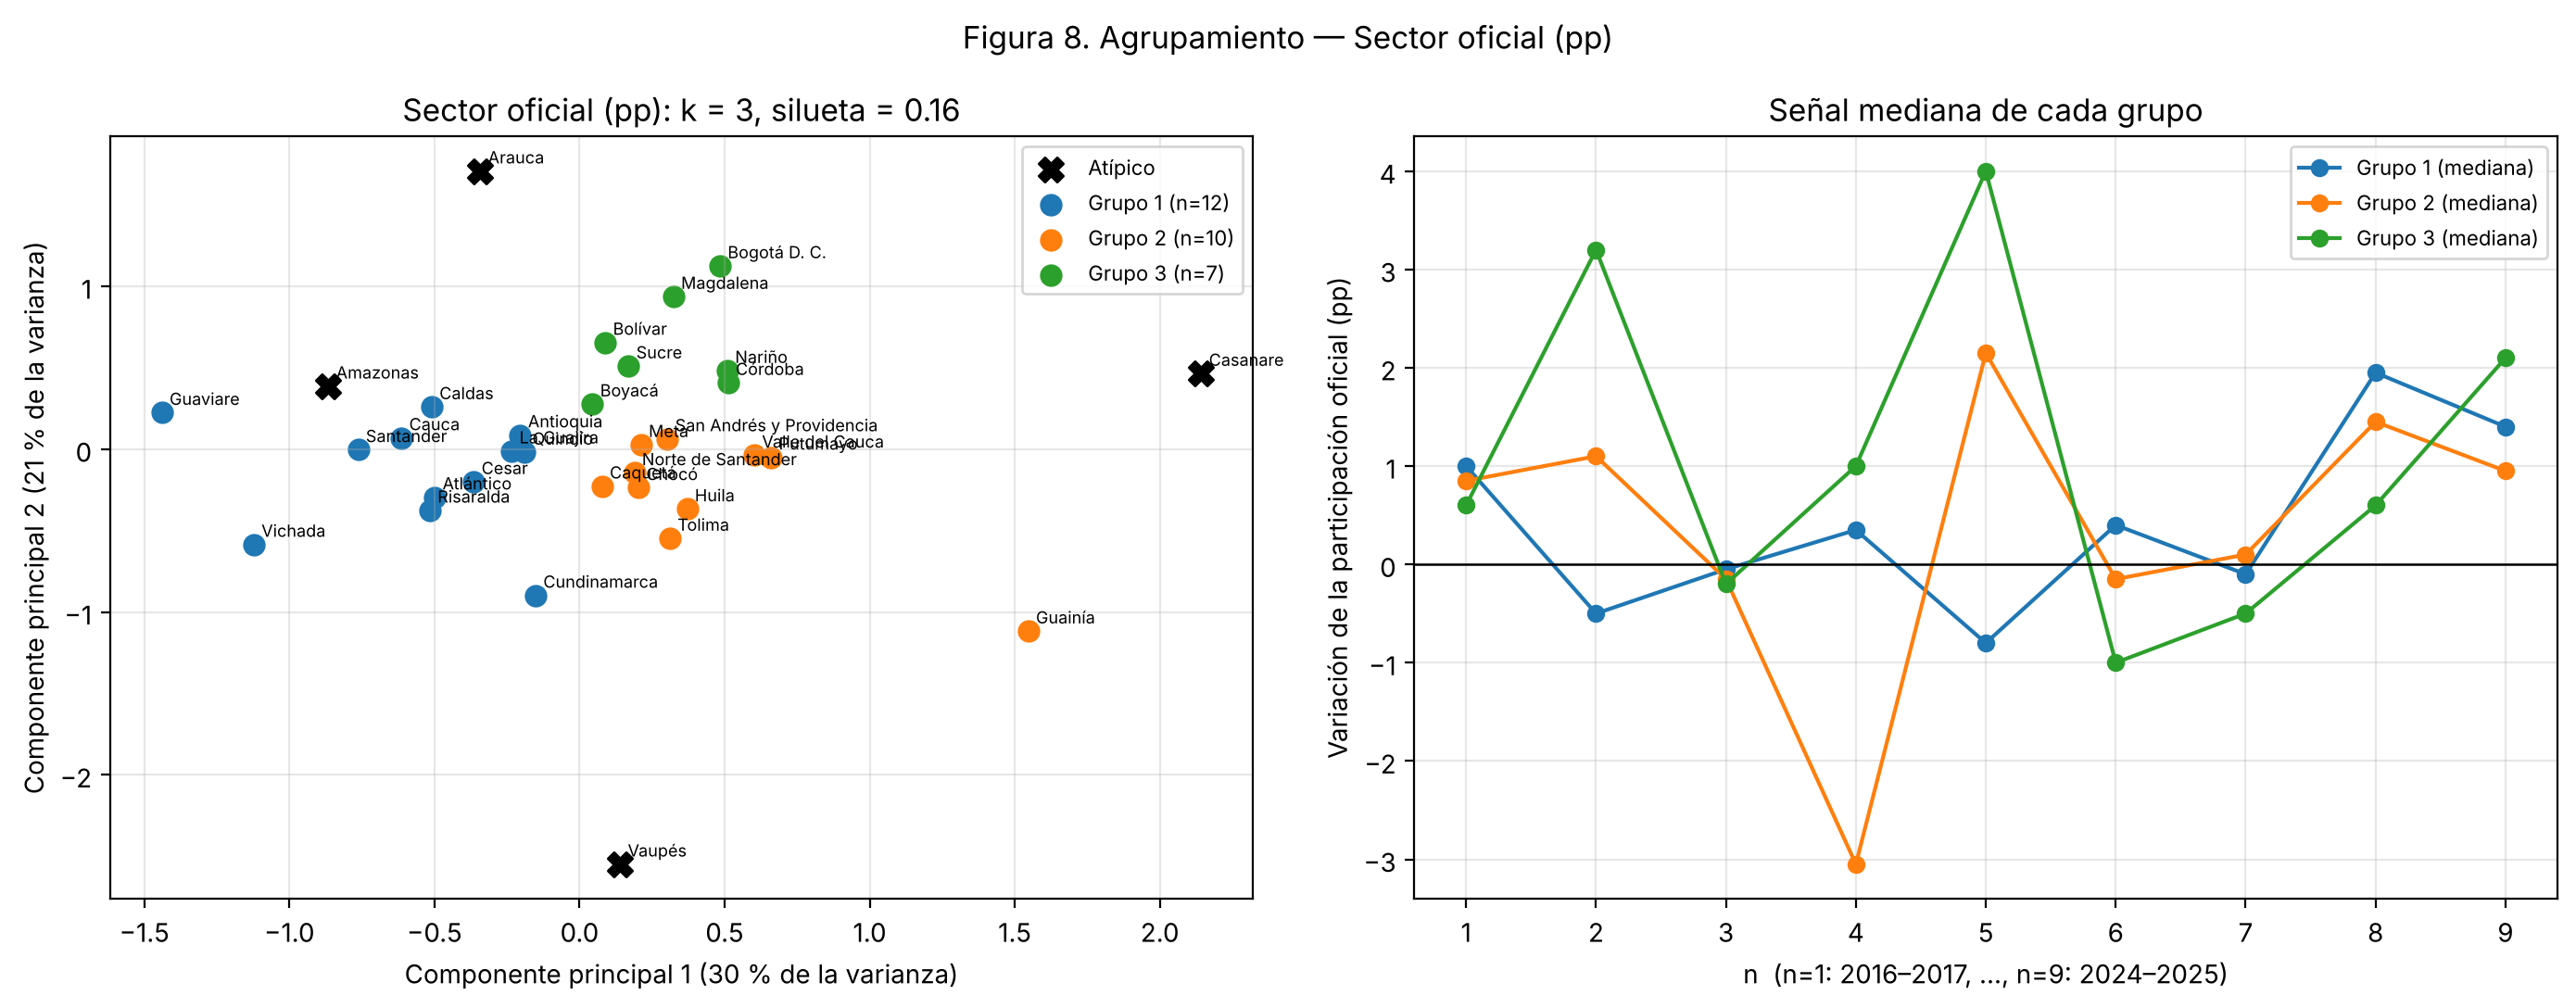

In [19]:
def graficar_agrupamiento(nombre, r, ylabel, numero):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.5))
    colores = plt.cm.tab10
    for g in sorted(set(r["etiquetas"])):
        m = r["etiquetas"] == g
        if g == 0:
            a1.scatter(r["pca"][m, 0], r["pca"][m, 1], marker="X", s=90, c="k", label="Atípico")
        else:
            a1.scatter(r["pca"][m, 0], r["pca"][m, 1], s=60, color=colores(g - 1), label=f"Grupo {g} (n={m.sum()})")
    for (px, py), dep in zip(r["pca"], r["nombres"]):
        a1.annotate(dep, (px, py), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
    a1.set_xlabel(f"Componente principal 1 ({r['var_exp'][0]*100:.0f} % de la varianza)")
    a1.set_ylabel(f"Componente principal 2 ({r['var_exp'][1]*100:.0f} % de la varianza)")
    a1.set_title(f"{nombre}: k = {r['k']}, silueta = {r['silueta']:.2f}"); a1.grid(alpha=0.3); a1.legend(fontsize=8)
    n = np.arange(1, 10)
    for g in sorted(set(r["etiquetas"])):
        if g == 0: continue
        med = np.median(r["X_original"][r["etiquetas"] == g], axis=0)
        a2.plot(n, med, "o-", color=colores(g - 1), label=f"Grupo {g} (mediana)")
    a2.axhline(0, color="k", lw=0.9); a2.set_xticks(n); a2.grid(alpha=0.3); a2.legend(fontsize=8)
    a2.set_xlabel("n  (n=1: 2016–2017, …, n=9: 2024–2025)"); a2.set_ylabel(ylabel)
    a2.set_title("Señal mediana de cada grupo")
    fig.suptitle(f"Figura {numero}. Agrupamiento — {nombre}", fontsize=12)
    fig.tight_layout(); fig.savefig(f"figuras/fig{numero}_agrupamiento_{numero-4}.png", dpi=150); plt.show()

graficar_agrupamiento("Técnica profesional", PROBLEMAS["Técnica profesional"], "Tasa de crecimiento (%)", 5)
graficar_agrupamiento("Tecnológica", PROBLEMAS["Tecnológica"], "Tasa de crecimiento (%)", 6)
graficar_agrupamiento("Universitaria", PROBLEMAS["Universitaria"], "Tasa de crecimiento (%)", 7)
graficar_agrupamiento("Sector oficial (pp)", PROBLEMAS["Sector oficial (pp)"], "Variación de la participación oficial (pp)", 8)

### Contexto territorial (para interpretar los grupos)

Las preguntas de la guía piden relacionar los grupos con características geográficas, económicas y socioeconómicas. Se usan tres variables **verificables**:

| Variable | Fuente |
|---|---|
| **Región natural** | Clasificación geográfica estándar de Colombia (Andina, Caribe, Pacífica, Orinoquía, Amazonía, Insular). |
| **Participación en el PIB nacional, 2024 (preliminar, %)** | DANE, *Boletín técnico: Producto Interno Bruto departamental 2024p* (`dane.gov.co/files/operaciones/PIB/bol-PIBDep-2024pr.pdf`). Calculada como PIB departamental / PIB nacional con la Tabla 1 del boletín, redondeada a un decimal. |
| **Incidencia de pobreza monetaria 2024 (%)** | DANE, *Comunicado de prensa: Pobreza monetaria departamental 2024* (`dane.gov.co/files/operaciones/PM/cp-PMDepartamental-2024.pdf`). El DANE publica 24 territorios; **no** hay dato para Amazonas, Arauca, Casanare, Guainía, Guaviare, Putumayo, San Andrés y Providencia, Vaupés y Vichada. |

⚠️ Verifiquen las cifras puntuales contra las fuentes antes de citarlas en el informe final: las de pobreza se transcribieron de las etiquetas de un gráfico. En el análisis se usan sobre todo **rangos y comparaciones gruesas**, no valores exactos. Estas variables describen a los departamentos; **no demuestran causalidad** con la dinámica de la matrícula.

In [20]:
REGION = {
    "Andina": ["Antioquia", "Boyacá", "Caldas", "Cundinamarca", "Bogotá D. C.", "Huila", "Norte de Santander", "Quindío", "Risaralda", "Santander", "Tolima"],
    "Caribe": ["Atlántico", "Bolívar", "Cesar", "Córdoba", "La Guajira", "Magdalena", "Sucre"],
    "Pacífica": ["Cauca", "Chocó", "Nariño", "Valle del Cauca"],
    "Orinoquía": ["Arauca", "Casanare", "Meta", "Vichada"],
    "Amazonía": ["Amazonas", "Caquetá", "Guainía", "Guaviare", "Putumayo", "Vaupés"],
    "Insular": ["San Andrés y Providencia"],
}
PIB_2024 = {  # % del PIB nacional, 2024 preliminar (DANE)
    "Bogotá D. C.": 25.2, "Antioquia": 14.8, "Valle del Cauca": 9.7, "Santander": 6.4, "Cundinamarca": 6.3, "Atlántico": 4.5,
    "Bolívar": 3.6, "Meta": 3.2, "Boyacá": 2.7, "Tolima": 2.2, "Cauca": 1.8, "Cesar": 1.8, "Córdoba": 1.8, "Huila": 1.7,
    "Caldas": 1.7, "Risaralda": 1.7, "Norte de Santander": 1.6, "Nariño": 1.5, "Magdalena": 1.4, "Casanare": 1.4,
    "La Guajira": 1.0, "Quindío": 0.9, "Sucre": 0.8, "Arauca": 0.5, "Chocó": 0.4, "Caquetá": 0.4, "Putumayo": 0.4,
    "San Andrés y Providencia": 0.1, "Guaviare": 0.1, "Amazonas": 0.1, "Vichada": 0.1, "Guainía": 0.0, "Vaupés": 0.0}
POBREZA_2024 = {  # % de personas en pobreza monetaria, 2024 (DANE); solo 24 territorios
    "Chocó": 67.4, "La Guajira": 65.7, "Sucre": 57.5, "Magdalena": 51.7, "Córdoba": 49.6, "Bolívar": 48.0, "Cesar": 47.8,
    "Cauca": 43.1, "Huila": 40.4, "Nariño": 39.2, "Caquetá": 37.4, "Tolima": 35.6, "Norte de Santander": 35.3, "Atlántico": 31.6,
    "Boyacá": 30.9, "Santander": 27.4, "Quindío": 25.9, "Valle del Cauca": 25.7, "Antioquia": 24.7, "Risaralda": 23.8,
    "Meta": 23.6, "Cundinamarca": 20.1, "Caldas": 20.0, "Bogotá D. C.": 19.6}

contexto = pd.DataFrame({"departamento": TERRITORIOS})
contexto["region"] = contexto.departamento.map({d: r for r, ds in REGION.items() for d in ds})
contexto["pib_2024_pct"] = contexto.departamento.map(PIB_2024)
contexto["pobreza_2024_pct"] = contexto.departamento.map(POBREZA_2024)
assert contexto.region.notna().all() and contexto.pib_2024_pct.notna().all()
contexto.to_csv("contexto_territorial.csv", index=False, encoding="utf-8")

def composicion(nombre):
    s = asig[asig.agrupamiento == nombre].merge(contexto, on="departamento")
    filas = []
    for g, sub in s.groupby("grupo"):
        filas.append(dict(grupo=g, n=len(sub),
                          regiones=", ".join(f"{k} {v}" for k, v in sub.region.value_counts().items()),
                          pib_prom_pct=sub.pib_2024_pct.mean(), pib_mediano_pct=sub.pib_2024_pct.median(),
                          pobreza_mediana_pct=sub.pobreza_2024_pct.median(), n_con_pobreza=int(sub.pobreza_2024_pct.notna().sum())))
    return pd.DataFrame(filas).set_index("grupo").round(1)

for nombre in PROBLEMAS:
    print(f"\n=== {nombre} ==="); display(composicion(nombre))


=== Técnica profesional ===


,n,regiones,pib_prom_pct,pib_mediano_pct,pobreza_mediana_pct,n_con_pobreza
grupo,,,,,,
Atípico,1,Pacífica 1,1.8,1.8,43.1,1
Grupo 1,22,"Andina 10, Caribe 6, Pacífica 3, Amazonía 1, O...",4.2,1.8,33.4,20
Grupo 2,4,"Amazonía 1, Orinoquía 1, Caribe 1, Andina 1",1.1,1.2,37.4,3



=== Tecnológica ===


,n,regiones,pib_prom_pct,pib_mediano_pct,pobreza_mediana_pct,n_con_pobreza
grupo,,,,,,
Grupo 1,27,"Andina 10, Caribe 7, Amazonía 3, Orinoquía 3, ...",2.7,1.7,35.3,21
Grupo 2,6,"Amazonía 3, Orinoquía 1, Andina 1, Pacífica 1",4.5,0.4,37.4,3



=== Universitaria ===


,n,regiones,pib_prom_pct,pib_mediano_pct,pobreza_mediana_pct,n_con_pobreza
grupo,,,,,,
Atípico,1,Amazonía 1,0.0,0.0,NaN,0
Grupo 1,27,"Andina 11, Caribe 7, Pacífica 4, Orinoquía 3, ...",3.7,1.7,35.4,24
Grupo 2,5,"Amazonía 3, Insular 1, Orinoquía 1",0.1,0.1,NaN,0



=== Sector oficial (pp) ===


,n,regiones,pib_prom_pct,pib_mediano_pct,pobreza_mediana_pct,n_con_pobreza
grupo,,,,,,
Atípico,4,"Amazonía 2, Orinoquía 2",0.5,0.3,NaN,0
Grupo 1,12,"Andina 6, Caribe 3, Pacífica 1, Amazonía 1, Or...",3.4,1.8,26.6,10
Grupo 2,10,"Amazonía 3, Andina 3, Pacífica 2, Orinoquía 1,...",2.0,1.0,35.6,7
Grupo 3,7,"Caribe 4, Andina 2, Pacífica 1",5.3,1.8,48.0,7


## Resultados e interpretación de los cuatro agrupamientos

| Agrupamiento | n | Atípicos | k | Silueta | ARI vs Ward |
|---|---|---|---|---|---|
| Técnica profesional | 27 | Cauca | 2 | 0,26 | 0,79 |
| Tecnológica | 33 | — | 2 | 0,33 | 0,70 |
| Universitaria | 33 | Vaupés | 2 | 0,49 | 1,00 |
| Sector oficial (pp) | 33 | Amazonas, Arauca, Casanare, Vaupés | 3 | 0,16 | 0,38 |

**Cómo leer estos resultados.** Las siluetas son bajas o moderadas (0,16–0,49): los grupos son **particiones descriptivas** de señales que forman un continuo, no clases bien separadas. El agrupamiento universitario es el más robusto (coincide exactamente con Ward); el del sector oficial es el más débil (silueta 0,16 y ARI 0,38), por lo que sus grupos deben leerse con cautela. Las variables de contexto (región, PIB, pobreza) **describen** a los grupos; no demuestran por qué se comportan así. Se distingue entre **hecho observado**, **interpretación** e **hipótesis por verificar**.

---
### 4.1 Técnica profesional (27 departamentos; 6 excluidos en la Tarea 2)

*Grupos:* Grupo 1 (22) · Grupo 2 (Caquetá, Casanare, Cesar, Quindío) · Atípico: Cauca.

**Pregunta 1: características compartidas.**
- *Hecho observado.* El Grupo 2 comparte un patrón temporal de caída casi continua (mediana de sus promedios: −52 %) hasta una matrícula técnica prácticamente nula: en 2025 Casanare tiene 3 matriculados y Caquetá, Cesar y Quindío 0. Sus bases eran pequeñas (en 2016: Quindío 1 092, Casanare 869, Caquetá 59, Cesar 61).
- *Hecho observado.* **No comparten región ni perfil socioeconómico:** Amazonía, Orinoquía, Caribe y Andina; participación en el PIB entre 0,4 % y 1,8 %; pobreza monetaria 2024 de 25,9 % (Quindío) a 47,8 % (Cesar) en los tres con dato.
- El Grupo 1 (22) reúne a las mayores economías (Bogotá, Antioquia, Valle del Cauca, Santander, Atlántico) y también a algunos de los departamentos más pobres (Chocó, Sucre, La Guajira, Magdalena): la dinámica de la formación técnica profesional **no separa a los departamentos según su tamaño económico o su región** con esta resolución.

**Pregunta 2: pertenencias inesperadas.**
- *Quindío*, andino y con pobreza relativamente baja, queda junto a Casanare, Cesar y Caquetá, de contextos muy distintos. **Interpretación:** la afinidad es del patrón temporal (desaparición de una oferta pequeña), no territorial. **Tres de los cuatro miembros** (Caquetá, Cesar y Quindío) **tienen tasas estimadas** por la regla de divisiones por cero, que además tiende a producir valores de −100 %, de modo que su pertenencia depende en parte de esa regla.
- *Cauca (atípico).* Su señal incluye la tasa estimada de **+5 900 %** (2022–2023) y una de −100 %. Su carácter atípico es un **artefacto de la regla de estimación aplicada a bases de uno a decenas de estudiantes** y no debe interpretarse como una característica del territorio.

---
### 4.2 Tecnológica (33 departamentos)

*Grupos:* Grupo 1 (27) · Grupo 2 (Arauca, Bogotá D. C., Caquetá, Chocó, Putumayo, Vaupés).

**Pregunta 1: características compartidas.**
- *Hecho observado.* El contraste entre grupos está sobre todo en **2020–2021 (n=5)**: la mediana del Grupo 2 es **+18,0 %** y la del Grupo 1 **−16,9 %**; el Grupo 2 también muestra una caída en 2019–2020 (mediana −15,5 %) y una recuperación en 2024–2025 (+12,5 %).
- *Hecho observado.* Cinco de los seis miembros del Grupo 2 son territorios periféricos (Amazonía 3, Orinoquía 1, Pacífica 1) con participación en el PIB de 0,5 % o menos (Arauca 0,5; Caquetá, Chocó y Putumayo 0,4; Vaupés ≈ 0), y el sexto es Bogotá (25,2 %). El Grupo 1 es heterogéneo: Andina 10, Caribe 7, Amazonía 3, Orinoquía 3 y otras, e incluye grandes economías (Antioquia, Valle del Cauca, Santander, Atlántico).

**Pregunta 2: pertenencias inesperadas.**
- *Bogotá D. C.*, la mayor economía del país, queda con territorios de bajo PIB. **Interpretación:** la afinidad es de dos intervalos (+77 % en 2020–2021 y +22 % en 2024–2025); en el resto del periodo su matrícula casi no cambia. **Hecho observado:** ese salto coincide con el aumento de su participación oficial de 30,7 % a 40,7 %. **Hipótesis por verificar:** cambios en el reporte o la oferta del sector oficial (por ejemplo, cómo reporta el SENA al SNIES).
- *Chocó*, el departamento con mayor pobreza monetaria entre los 24 con dato (67,4 %), queda en el mismo grupo que Bogotá (19,6 %): confirma que el agrupamiento responde a la forma temporal y no al perfil socioeconómico.

---
### 4.3 Universitaria (33 departamentos)

*Grupos:* Grupo 1 (27) · Grupo 2 (Guainía, Guaviare, Putumayo, San Andrés y Providencia, Vichada) · Atípico: Vaupés.

**Pregunta 1: características compartidas.**
- *Hecho observado.* El Grupo 2 combina **bases muy pequeñas** (79 a 1 210 matriculados universitarios en 2016; hasta 4 947 en 2025) con **crecimiento alto y sostenido desde 2019–2020**: medianas de +38,8 %, +45,6 %, +18,1 %, +14,8 % y +24,2 % entre n=4 y n=8, y mediana de sus promedios de 16,2 % frente a 2,5 % en el Grupo 1.
- *Hecho observado.* Son territorios con participación en el PIB de 0,4 % o menos (tres de la Amazonía, uno de la Orinoquía y San Andrés y Providencia). **El DANE no publica pobreza monetaria por separado para ninguno de ellos**, de modo que no hay dato socioeconómico comparable.
- El Grupo 1 (27) incluye a todas las grandes economías y a los 11 departamentos andinos, los 7 caribeños y los 4 de la región Pacífica: crecimiento moderado y estable, con medianas de entre 0,0 % y 4,5 %, y su valor más alto en 2024–2025.

**Pregunta 2: pertenencias inesperadas.**
- *San Andrés y Providencia* es el único miembro del Grupo 2 que no es amazónico ni orinoquense. Según el DANE, su PIB por habitante supera el promedio nacional. **Interpretación:** su pertenencia se debe a la base minúscula (79 matriculados en 2016 y 114 en 2025): variaciones de entre −25 % y +46 % equivalen a decenas de estudiantes. Además su crecimiento **no es sostenido** (−20 % en 2022–2023 y −3 % en 2024–2025), a diferencia de Putumayo, que más que cuadruplica su matrícula (1 210 → 4 947).
- *Vaupés (atípico).* **+486 %** en 2019–2020 (de 36 a 211), en el mismo intervalo en que su participación oficial cae de 100 % a 39,3 %. **Hipótesis por verificar:** entrada de un nuevo oferente o programa privado en un territorio con muy pocos estudiantes.

---
### 4.4 Participación del sector oficial (33 departamentos)

*Grupos:* Grupo 1 (12) · Grupo 2 (10) · Grupo 3 (7) · Atípicos: Amazonas, Arauca, Casanare, Vaupés. **La estructura es débil (silueta 0,16; ARI 0,38):** los grupos describen tendencias, no categorías nítidas.

**Pregunta 1: características compartidas.**
- *Grupo 1 (Antioquia, Atlántico, Caldas, Cauca, Cesar, Cundinamarca, Guaviare, La Guajira, Quindío, Risaralda, Santander, Vichada).* Participación casi estable (medianas de |ΔO| ≤ 1 pp en la mayoría de intervalos, con +2,0 y +1,4 pp en los dos últimos). Predominan regiones andinas (6) y es el grupo con **menor pobreza mediana** (26,6 %, con dato en 10 de 12).
- *Grupo 2 (Caquetá, Chocó, Guainía, Huila, Meta, Norte de Santander, Putumayo, San Andrés y Providencia, Tolima, Valle del Cauca).* Su señal típica tiene una **caída de 3,0 pp en 2019–2020 seguida de un aumento de 2,2 pp en 2020–2021**. Es el grupo más mixto (Amazonía 3, Andina 3, Pacífica 2, Orinoquía 1, Insular 1); pobreza mediana de 35,6 % (7 con dato).
- *Grupo 3 (Bogotá D. C., Bolívar, Boyacá, Córdoba, Magdalena, Nariño, Sucre).* Aumentos marcados en **2017–2018 (+3,2 pp) y 2020–2021 (+4,0 pp)**. Predominan los departamentos caribeños (4 de 7) y tiene la **mayor pobreza mediana** (48,0 %, con dato en los 7).
- *Atípicos:* los cuatro son amazónicos u orinoquenses de matrícula pequeña, con cambios acumulados de +40,7 pp (Amazonas), +57,6 pp (Arauca), +46,2 pp (Casanare) y −71,3 pp (Vaupés).

**Pregunta 2: pertenencias inesperadas.**
- *La Guajira* (pobreza monetaria de 65,7 %, la segunda más alta) queda en el Grupo 1, junto a departamentos andinos de bajo nivel de pobreza. **Interpretación:** su participación oficial ya estaba entre 96,8 % y 98,4 % durante todo el periodo, de modo que **no hay margen para variar** (efecto de techo): la estabilidad de la señal no refleja similitud socioeconómica con sus compañeros de grupo. Lo mismo ocurre con Guaviare y Vichada, con participaciones de 94 % a 100 %.
- *Bogotá D. C.* queda en el Grupo 3 con departamentos caribeños y pobres. **Hecho observado:** su salto de +10,0 pp en 2020–2021 (30,7 % → 40,7 %) coincide con la forma típica del grupo en n=5. **Hipótesis por verificar:** el mismo cambio en el reporte u oferta del sector oficial señalado en 4.2.
- *Valle del Cauca* (tercera economía) queda en el Grupo 2 con territorios amazónicos como Putumayo, Caquetá y Guainía: comparten la caída de 2019–2020 y la recuperación de 2020–2021, año marcado por la pandemia. **Hipótesis por verificar:** efecto de la pandemia sobre la composición pública-privada de la matrícula.
- *Atípicos.* Con muy pocos estudiantes, la entrada o salida de una sola institución o programa mueve la participación oficial decenas de puntos; los cuatro atípicos son consistentes con esa hipótesis, que **no puede verificarse** con las variables disponibles.

**Recordatorio de rigor.** Las relaciones entre grupos y variables de contexto son **descriptivas**; no se afirma causalidad. Las cifras de PIB y pobreza provienen del DANE (ver fuentes al final) y conviene contrastarlas antes de citarlas puntualmente.

---
# Tarea 5. Análisis del posible impacto de la Ley 2307 de 2023

Se examina si los crecimientos interanuales **posteriores a 2023** (intervalos 2023–2024 y 2024–2025, $g_d[8]$ y $g_d[9]$) superan el **comportamiento histórico** de cada par departamento–nivel, definido como la media de las siete tasas anteriores (2016–2017 a 2022–2023):

$$\overline{g}_{d,\mathrm{hist}}=\frac{1}{7}\sum_{n=1}^{7}g_d[n].$$

Se seleccionan los pares que cumplen **simultáneamente** $g_d[8]>\overline{g}_{d,\mathrm{hist}}$ y $g_d[9]>\overline{g}_{d,\mathrm{hist}}$. Se usa el Dataset 2 tal como se construyó (incluidas las tasas estimadas, que se **marcan** en la tabla y las gráficas).

In [21]:
nueve = d2.copy()
nueve["hist_media"] = nueve[INTERVALOS[:7]].mean(axis=1)
nueve["g_2023_2024"] = nueve["2023_2024"]; nueve["g_2024_2025"] = nueve["2024_2025"]
nueve["dif_2023_2024"] = nueve.g_2023_2024 - nueve.hist_media
nueve["dif_2024_2025"] = nueve.g_2024_2025 - nueve.hist_media
nueve["estimado_en_hist"] = [any((a, b, i) in est_set for i in INTERVALOS[:7]) for a, b in zip(nueve.departamento, nueve.nivel)]
nueve["estimado_post"] = [any((a, b, i) in est_set for i in INTERVALOS[7:]) for a, b in zip(nueve.departamento, nueve.nivel)]

sel5 = nueve[(nueve.g_2023_2024 > nueve.hist_media) & (nueve.g_2024_2025 > nueve.hist_media)].copy()
sel5["dif_min"] = sel5[["dif_2023_2024", "dif_2024_2025"]].min(axis=1)
sel5 = sel5.sort_values("dif_min", ascending=False)

print(f"Pares departamento–nivel analizados: {len(nueve)}")
print(f"Pares con g[8] > media histórica: {(nueve.g_2023_2024 > nueve.hist_media).sum()}")
print(f"Pares con g[9] > media histórica: {(nueve.g_2024_2025 > nueve.hist_media).sum()}")
print(f"Pares que cumplen AMBAS condiciones: {len(sel5)}")
print("\nPor nivel de formación:"); print(sel5.nivel.value_counts().to_string())

tabla5 = sel5[["departamento", "nivel", "hist_media", "g_2023_2024", "g_2024_2025", "dif_2023_2024", "dif_2024_2025", "estimado_en_hist"]].round(2)
tabla5.to_csv("tarea5_tabla_comparativa.csv", index=False, encoding="utf-8")
tabla5.reset_index(drop=True)

Pares departamento–nivel analizados: 93
Pares con g[8] > media histórica: 62
Pares con g[9] > media histórica: 61
Pares que cumplen AMBAS condiciones: 45

Por nivel de formación:
nivel
Tecnológica            21
Universitaria          16
Técnica profesional     8


,departamento,nivel,hist_media,g_2023_2024,g_2024_2025,dif_2023_2024,dif_2024_2025,estimado_en_hist
0,Amazonas,Técnica profesional,-44.76,-3.33,72.41,41.43,117.17,True
1,Huila,Técnica profesional,-4.32,16.86,12.44,21.18,16.75,False
2,Atlántico,Tecnológica,-4.84,9.75,12.76,14.60,17.60,False
3,Arauca,Tecnológica,-7.00,7.31,37.04,14.31,44.04,False
4,Vichada,Tecnológica,-9.86,14.74,3.35,24.60,13.21,False
5,Caldas,Técnica profesional,10.01,36.97,21.93,26.96,11.91,False
6,Valle del Cauca,Técnica profesional,1.14,12.85,26.79,11.71,25.65,False
7,Nariño,Técnica profesional,-12.16,-0.63,57.59,11.53,69.75,True
8,La Guajira,Tecnológica,-5.53,5.66,16.24,11.19,21.77,False
9,Nariño,Tecnológica,-4.84,5.21,5.56,10.05,10.40,False


In [22]:
# Verificación manual de un caso
r = sel5.iloc[0]
y = r[INTERVALOS].values.astype(float)
print(f"{r.departamento} · {r.nivel}: media(7 primeras) = {y[:7].mean():.4f} (tabla: {r.hist_media:.4f}); g8 = {y[7]:.2f} > media, g9 = {y[8]:.2f} > media")
assert abs(y[:7].mean() - r.hist_media) < 1e-9 and y[7] > r.hist_media and y[8] > r.hist_media

Amazonas · Técnica profesional: media(7 primeras) = -44.7611 (tabla: -44.7611); g8 = -3.33 > media, g9 = 72.41 > media


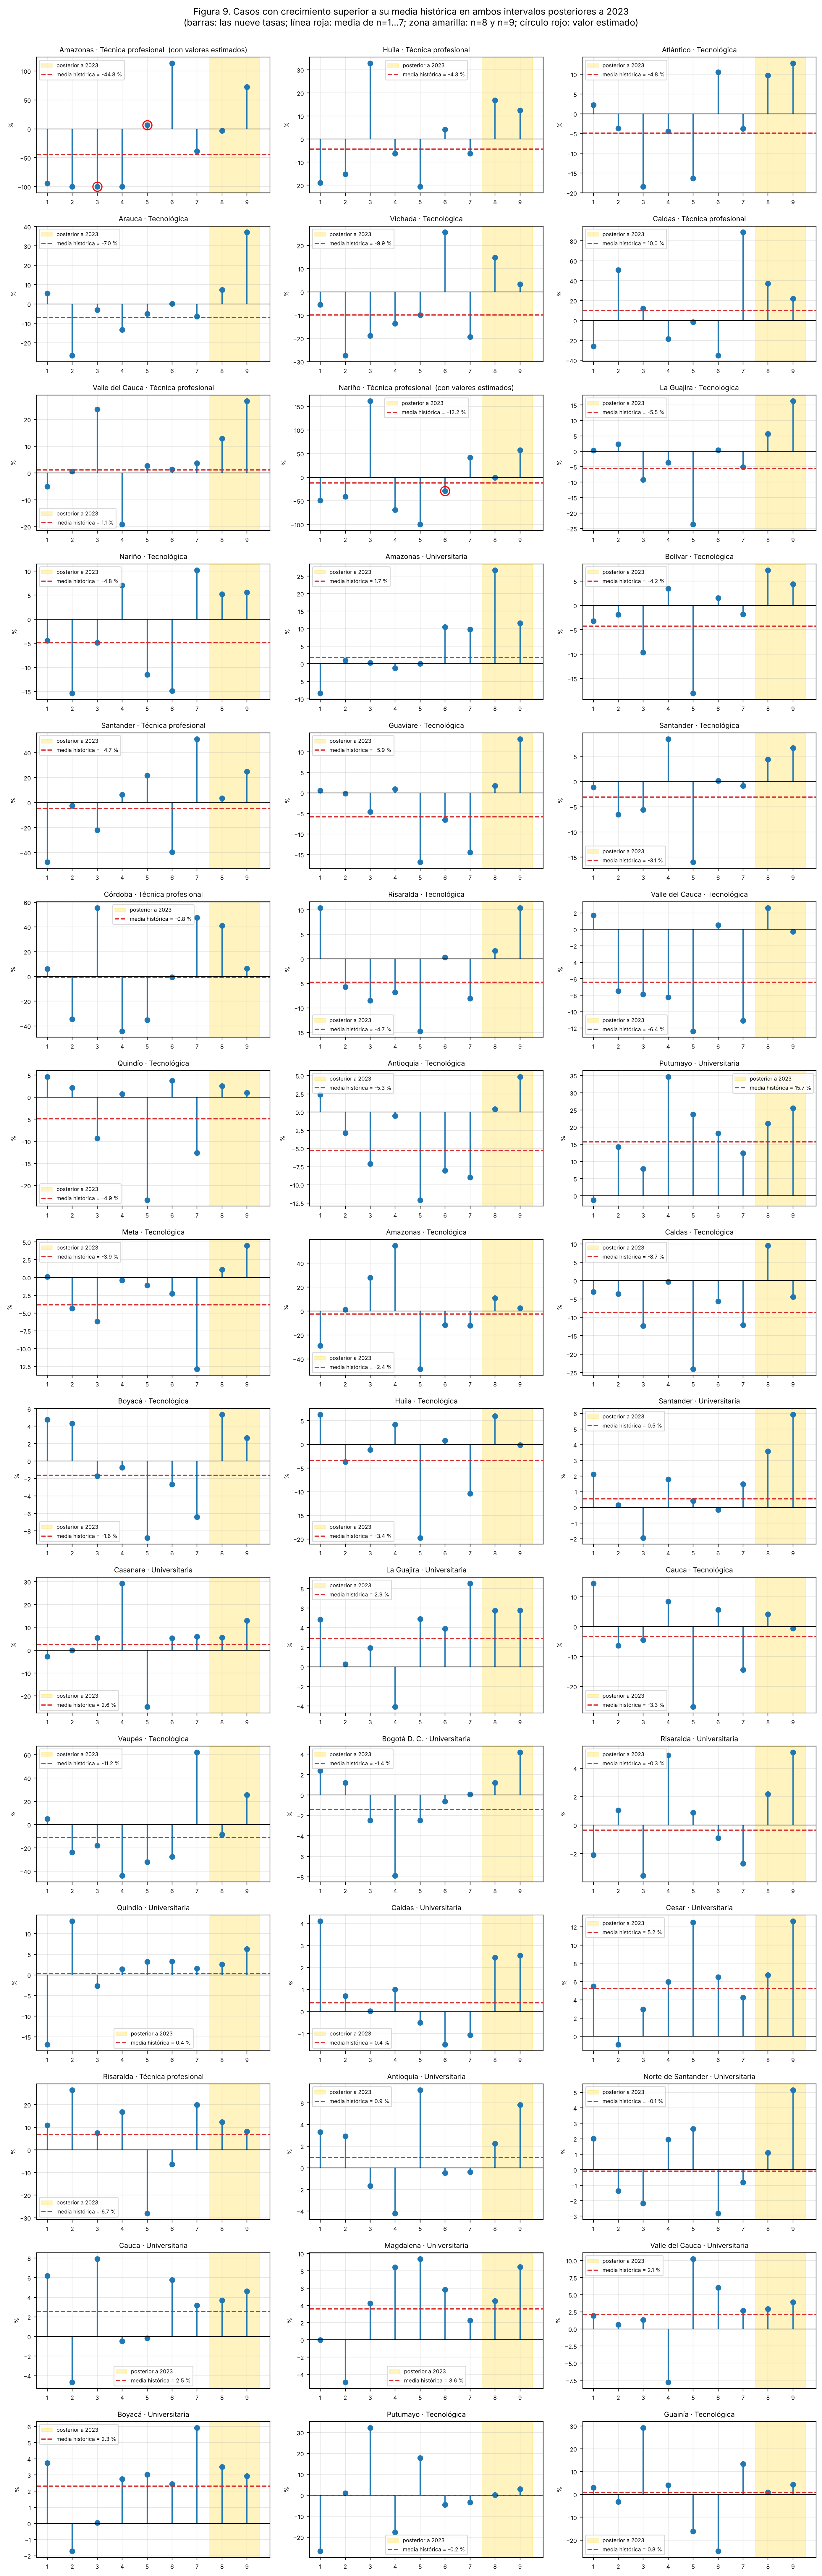

In [23]:
def grafico_caso(ax, r):
    y = r[INTERVALOS].values.astype(float); n = np.arange(1, 10)
    marcas = np.array([(r.departamento, r.nivel, i) in est_set for i in INTERVALOS])
    ax.axvspan(7.5, 9.5, color="gold", alpha=0.25, label="posterior a 2023")
    ml, sl, bl = ax.stem(n, y, basefmt=" ")
    plt.setp(ml, color="C0"); plt.setp(sl, color="C0")
    ax.axhline(0, color="k", lw=0.8)
    ax.axhline(r.hist_media, color="C3", ls="--", lw=1.4, label=f"media histórica = {r.hist_media:.1f} %")
    if marcas.any():
        ax.plot(n[marcas], y[marcas], "o", mfc="none", mec="red", ms=11, mew=1.4)
    ax.set_xticks(n); ax.grid(alpha=0.3)
    ax.set_title(f"{r.departamento} · {r.nivel}" + ("  (con valores estimados)" if marcas.any() else ""), fontsize=8.5)
    ax.tick_params(labelsize=7); ax.legend(fontsize=6.5, loc="best")

filas = int(np.ceil(len(sel5) / 3))
fig, axs = plt.subplots(filas, 3, figsize=(14, 2.9 * filas))
axs = np.atleast_2d(axs).ravel()
for ax, (_, r) in zip(axs, sel5.iterrows()):
    grafico_caso(ax, r)
for ax in axs[len(sel5):]: ax.axis("off")
for ax in axs[:len(sel5)]: ax.set_ylabel("%", fontsize=7)
fig.suptitle("Figura 9. Casos con crecimiento superior a su media histórica en ambos intervalos posteriores a 2023\n"
             "(barras: las nueve tasas; línea roja: media de n=1…7; zona amarilla: n=8 y n=9; círculo rojo: valor estimado)", fontsize=11, y=1.0)
fig.tight_layout(); fig.savefig("figuras/fig9_ley2307_casos.png", dpi=150, bbox_inches="tight"); plt.show()

In [24]:
# Contexto para la interpretación: dónde se concentran los casos y qué tan grandes son las diferencias
print("Casos seleccionados por nivel y región:")
display(sel5.merge(contexto, on="departamento").groupby(["nivel", "region"]).size().unstack(fill_value=0))
print("\nTop 8 por diferencia mínima (el menor de los dos excesos sobre la media histórica, en puntos porcentuales de tasa):")
display(sel5.head(8)[["departamento", "nivel", "hist_media", "g_2023_2024", "g_2024_2025", "dif_2023_2024", "dif_2024_2025", "estimado_en_hist"]].round(1))

# Comparación de contexto: tasas medias por nivel antes y después (todos los pares)
resumen5 = nueve.groupby("nivel")[["hist_media", "g_2023_2024", "g_2024_2025"]].median().round(2)
resumen5.columns = ["mediana de medias históricas (%)", "mediana 2023–2024 (%)", "mediana 2024–2025 (%)"]
print("\nMediana entre departamentos, por nivel:"); display(resumen5)

# Tamaño de matrícula de los casos seleccionados (los crecimientos desde bases pequeñas son más ruidosos)
base2023 = d1[d1.año == 2023].set_index("departamento")
sel5["matricula_2023"] = [base2023.loc[dep, {"Técnica profesional": "tecnica", "Tecnológica": "tecnologica", "Universitaria": "universitaria"}[n]] for dep, n in zip(sel5.departamento, sel5.nivel)]
print("\nMatrícula 2023 de los casos seleccionados (por nivel, mediana y mínimo):")
display(sel5.groupby("nivel").matricula_2023.agg(["count", "median", "min"]))

Casos seleccionados por nivel y región:


region,Amazonía,Andina,Caribe,Orinoquía,Pacífica
nivel,,,,,
Tecnológica,5,7,3,3,3
Técnica profesional,1,4,1,0,2
Universitaria,2,8,3,1,2



Top 8 por diferencia mínima (el menor de los dos excesos sobre la media histórica, en puntos porcentuales de tasa):


,departamento,nivel,hist_media,g_2023_2024,g_2024_2025,dif_2023_2024,dif_2024_2025,estimado_en_hist
0,Amazonas,Técnica profesional,-44.8,-3.3,72.4,41.4,117.2,True
14,Huila,Técnica profesional,-4.3,16.9,12.4,21.2,16.8,False
30,Atlántico,Tecnológica,-4.8,9.8,12.8,14.6,17.6,False
29,Arauca,Tecnológica,-7.0,7.3,37.0,14.3,44.0,False
59,Vichada,Tecnológica,-9.9,14.7,3.4,24.6,13.2,False
6,Caldas,Técnica profesional,10.0,37.0,21.9,27.0,11.9,False
26,Valle del Cauca,Técnica profesional,1.1,12.8,26.8,11.7,25.6,False
18,Nariño,Técnica profesional,-12.2,-0.6,57.6,11.5,69.8,True



Mediana entre departamentos, por nivel:


,mediana de medias históricas (%),mediana 2023–2024 (%),mediana 2024–2025 (%)
nivel,,,
Tecnológica,-3.87,5.21,2.64
Técnica profesional,1.83,-2.70,12.68
Universitaria,2.61,2.92,4.25



Matrícula 2023 de los casos seleccionados (por nivel, mediana y mínimo):


,count,median,min
nivel,,,
Tecnológica,21,5701.0,47
Técnica profesional,8,1011.0,30
Universitaria,16,34209.0,382


In [25]:
# Contexto nacional: suma de los 33 territorios por nivel (¿se acelera la matrícula agregada después de 2023?)
tot = d1.groupby("año")[["tecnica", "tecnologica", "universitaria"]].sum()
crec = (tot.pct_change() * 100).round(1).iloc[1:]
crec.index = INTERVALOS
print("Matrícula agregada (suma de los 33 territorios):"); display(tot.T)
print("Crecimiento interanual de la matrícula agregada (%):"); display(crec.T)

print("Sector oficial: mediana de ΔO entre departamentos y número de departamentos con ΔO > 0, por intervalo")
display(pd.DataFrame({"mediana_ΔO_pp": d3[INTERVALOS].median().round(2), "n_dptos_con_aumento": (d3[INTERVALOS] > 0).sum()}).T)

Matrícula agregada (suma de los 33 territorios):


año,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
tecnica,82585,73263,78618,81805,68903,74098,82994,90837,95389,106420
tecnologica,638499,658579,630928,574730,581479,617679,613092,583917,613932,677726
universitaria,1513201,1548485,1557594,1552078,1529788,1568193,1588551,1606093,1637436,1712508


Crecimiento interanual de la matrícula agregada (%):


,2016_2017,2017_2018,2018_2019,2019_2020,2020_2021,2021_2022,2022_2023,2023_2024,2024_2025
tecnica,-11.3,7.3,4.1,-15.8,7.5,12.0,9.5,5.0,11.6
tecnologica,3.1,-4.2,-8.9,1.2,6.2,-0.7,-4.8,5.1,10.4
universitaria,2.3,0.6,-0.4,-1.4,2.5,1.3,1.1,2.0,4.6


Sector oficial: mediana de ΔO entre departamentos y número de departamentos con ΔO > 0, por intervalo


,2016_2017,2017_2018,2018_2019,2019_2020,2020_2021,2021_2022,2022_2023,2023_2024,2024_2025
mediana_ΔO_pp,0.9,0.9,0.0,-0.6,1.8,0.0,0.1,1.5,1.4
n_dptos_con_aumento,25.0,22.0,16.0,14.0,24.0,16.0,20.0,25.0,29.0


In [26]:
# Diagnóstico auxiliar (no es parte de la guía): ¿qué tan frecuente era la condición "dos intervalos consecutivos por encima
# del promedio de las 4 tasas previas" en ventanas anteriores a 2023? (Con 9 tasas, un referente de 7 solo existe para n=8, 9.)
G = d2[INTERVALOS].values
ventanas = []
for j in range(4, 8):                       # j: índice (0-based) del primer intervalo de la pareja
    h = G[:, j - 4:j].mean(axis=1)
    cumple = (G[:, j] > h) & (G[:, j + 1] > h)
    por_nivel = d2.assign(cumple=cumple).groupby("nivel").cumple.sum().to_dict()
    ventanas.append(dict(pareja=f"{INTERVALOS[j]} y {INTERVALOS[j+1]}", pares_que_cumplen=int(cumple.sum()),
                         porcentaje_de_93=round(100 * cumple.mean()), **por_nivel))
display(pd.DataFrame(ventanas))

# Sensibilidad: referente con la mediana de las 7 tasas en lugar de la media
hm = np.median(G[:, :7], axis=1)
ok_med = (G[:, 7] > hm) & (G[:, 8] > hm)
print(f"Con la mediana de las 7 tasas como referente cumplen ambas condiciones: {ok_med.sum()} de {len(G)} pares")

,pareja,pares_que_cumplen,porcentaje_de_93,Tecnológica,Técnica profesional,Universitaria
0,2020_2021 y 2021_2022,28,30,5,7,16
1,2021_2022 y 2022_2023,26,28,8,9,9
2,2022_2023 y 2023_2024,28,30,10,10,8
3,2023_2024 y 2024_2025,43,46,23,8,12


Con la mediana de las 7 tasas como referente cumplen ambas condiciones: 53 de 93 pares


## Respuestas de la Tarea 5

### Pregunta 1. ¿Qué pares superaron su promedio histórico en ambos intervalos? ¿Cuáles tuvieron las mayores diferencias y qué patrones se observan?

**Hechos observados.** De los 93 pares departamento–nivel, **45 (48 %)** cumplen simultáneamente $g[8]>\bar g_{hist}$ y $g[9]>\bar g_{hist}$: **21 de 33 en tecnológica (64 %)**, **16 de 33 en universitaria (48 %)** y **8 de 27 en técnica profesional (30 %)**. La tabla completa está arriba (`tarea5_tabla_comparativa.csv`) y las 45 señales en la Figura 9.

**Mayores diferencias** (excesos sobre la media histórica, en puntos porcentuales de tasa):
- *Amazonas, técnica profesional* (+41,4 y +117,2) y *Nariño, técnica profesional* (+11,5 y +69,8): **hay que tomarlos con cautela**, porque sus medias históricas incluyen tasas estimadas por la regla de divisiones por cero (marcados en la tabla y la figura) y sus bases son de pocas decenas.
- *Arauca, tecnológica* (+14,3 y +44,0), *Vichada, tecnológica* (+24,6 y +13,2), *Atlántico, tecnológica* (+14,6 y +17,6), *Huila, técnica* (+21,2 y +16,8), *Caldas, técnica* (+27,0 y +11,9), *Valle del Cauca, técnica* (+11,7 y +25,6).

**Patrones.**
1. **Tecnológica concentra los casos, y la mayoría viene de una media histórica negativa.** La mediana de las medias históricas entre departamentos es −3,9 %, frente a +5,2 % en 2023–2024 y +2,6 % en 2024–2025. Superar su media significa, en muchos casos, **que el descenso previo se detuvo**: la matrícula tecnológica agregada de los 33 territorios cayó de 638 mil (2016) a 584 mil (2023) y luego subió +5,1 % y +10,4 %.
2. **Universitaria: mejoras pequeñas pero extendidas.** Mediana histórica de 2,6 %, luego 2,9 % y 4,3 %. En agregado, +2,0 % y +4,6 %, frente a un rango de −1,4 % a +2,5 % entre 2016 y 2023; **2024–2025 es el mayor crecimiento de toda la serie**. Los excesos individuales son de pocos puntos.
3. **Técnica profesional: pocos casos, bases pequeñas.** La mediana de matrícula 2023 de los 8 casos es de unos 1 000 estudiantes (mínimo 30), por lo que son muy ruidosos. En agregado, +5,0 % y +11,6 %.
4. **Sin concentración geográfica clara.** Los casos se reparten así: Andina 19, Amazonía 8, Caribe 7, Pacífica 7 y Orinoquía 4.
5. **Sector oficial.** La participación oficial aumenta en 25 de 33 departamentos en 2023–2024 y en **29 de 33 en 2024–2025** (el mayor conteo de la serie); la mediana de ΔO es de +1,5 y +1,4 pp.
6. **Diagnóstico auxiliar.** Con un referente de las cuatro tasas previas (el único posible en ventanas anteriores con solo nueve tasas), la condición doble se cumplía en 28 % a 30 % de los pares en las tres ventanas anteriores (que terminan en 2021–2022, 2022–2023 y 2023–2024) y en **46 %** en 2023–2025; la diferencia se concentra en tecnológica (23 pares frente a 5 a 10). Es decir, el patrón posterior a 2023 es **más frecuente** que en los años inmediatamente anteriores, y no solo la consecuencia de usar un promedio histórico bajo.

### Pregunta 2. ¿En qué medida podrían estar relacionados los cambios con la Ley 2307 de 2023?

**Alcance de la ley (según su texto y la política del MEN).** La Ley 2307 de 2023 regula la **gratuidad en programas de pregrado de instituciones de educación superior públicas** (técnica profesional, tecnológica y universitaria), financiada con recursos adicionales del Presupuesto General de la Nación, con implementación progresiva según la disponibilidad presupuestal (arts. 1–4). No cubre posgrados. Los requisitos de focalización no están en la ley sino en su reglamentación (Decreto 2271 de 2023 y Reglamento Operativo del 17 de enero de 2024); según el MEN, la gratuidad cubre a estudiantes de estratos 1 a 3 y otros grupos priorizados, **sin límite de edad** (el esquema previo la limitaba a 14–28 años), y aplica desde la expedición del reglamento sin carácter retroactivo, con periodos adicionales habilitados desde 2024.

**Argumentos a favor de una posible relación.**
- **Coincidencia temporal:** los primeros periodos con gratuidad reglamentada son 2024 en adelante, que corresponden justo a los intervalos 2023–2024 y 2024–2025.
- **Coincidencia de nivel:** la ley cubre los tres niveles de pregrado analizados.
- **Dirección del cambio:** aumenta la matrícula agregada en los tres niveles y sube la participación del sector oficial en casi todos los departamentos, que es el sector al que se dirige la política.

**Razones por las que no se puede atribuir el cambio a la ley.**
1. **No se aísla a los beneficiarios.** El Dataset 1 mezcla sectores oficial y privado y no distingue estratos ni beneficiarios; solo se observa la participación oficial.
2. **Hay antecedentes de gratuidad.** La guía recuerda que el Decreto 1667 de 2021 ya contemplaba una política de gratuidad; el MEN indica además que los beneficiarios de 2022 y 2023 (Fondo Solidario, Generación E) conservan su beneficio. **Hecho observado:** la participación oficial ya había subido en 2020–2021 (mediana +1,8 pp; 24 de 33 departamentos), antes de la ley.
3. **Otros factores posibles.** Recuperación posterior a la pandemia (la matrícula técnica agregada cayó 15,8 % en 2019–2020); cambios demográficos y económicos; ampliación de la oferta regional; cambios en el reporte de instituciones como el SENA al SNIES; y bases pequeñas donde unos pocos estudiantes producen grandes variaciones.
4. **El referente histórico es frágil.** La media de siete tasas incluye años de pandemia y atípicos; con la **mediana** de las siete tasas cumplen la condición 53 de 93 pares (57 %), no 45, de modo que el resultado depende de la definición del referente.
5. **No hay contrafactual.** Solo hay dos observaciones posteriores a 2023 y ningún grupo de control; los análisis aquí son descriptivos.

**Conclusión.** Después de 2023 **sí se observa** que cerca de la mitad de los pares departamento–nivel crecen por encima de su promedio histórico, con mayor frecuencia que en ventanas anteriores y con mayor intensidad en tecnológica, y que la participación oficial aumenta de forma generalizada. El calendario y el alcance de la ley son **consistentes** con una contribución de la gratuidad, pero **estos datos no permiten establecer que el aumento se deba a la ley, ni medir qué parte le correspondería**. Para avanzar harían falta datos de matrícula por sector y por beneficiario (SNIES y registros de gratuidad del MEN) y comparaciones con series que no hayan sido afectadas por la política.

---
# Cierre

## Archivos generados
| Archivo | Contenido |
|---|---|
| `dataset1.csv` | Dataset 1: 330 filas × 7 columnas |
| `dataset2.csv` · `dataset2_estimados.csv` · `dataset2_exclusiones.csv` | Dataset 2 (93 filas), tasas estimadas y filas excluidas |
| `dataset3.csv` | Dataset 3 (33 filas, en pp) |
| `asignacion_grupos.csv` | Asignación de departamentos a grupos en los cuatro agrupamientos |
| `contexto_territorial.csv` | Región, PIB 2024 y pobreza 2024 usados para interpretar los grupos |
| `tarea5_tabla_comparativa.csv` | Tabla de la Tarea 5 |
| `figuras/` | Figuras 1 a 9 |

## Fuentes
- SNIES – Ministerio de Educación Nacional, consultas públicas de *Matriculados* (`hecaa.mineducacion.gov.co/consultaspublicas`).
- DANE, *Boletín técnico: PIB departamental 2024p* (`dane.gov.co/files/operaciones/PIB/bol-PIBDep-2024pr.pdf`).
- DANE, *Comunicado de prensa: Pobreza monetaria departamental 2024* (`dane.gov.co/files/operaciones/PM/cp-PMDepartamental-2024.pdf`).
- Ley 2307 de 2023 (texto en Función Pública: `funcionpublica.gov.co/eva/gestornormativo/norma_pdf.php?i=215190`).
- Ministerio de Educación Nacional, *Política de Gratuidad "Puedo Estudiar"* (`mineducacion.gov.co`, sección Educación superior).

## Alcance y rigor
Se distinguieron hechos observados, interpretaciones e hipótesis por verificar. Las decisiones metodológicas (tratamiento de faltantes de la Tarea 1, regla de selección de la Tarea 3, transformación, detección de atípicos y criterio de k de la Tarea 4, y la definición del referente de la Tarea 5) están documentadas y pueden modificarse. Se usó inteligencia artificial como apoyo para la programación.